# C06b — NS4 → NS8 → NS10 on frozen C05 Ghostbuster

Run from `reproduction/experiments/` in a **fresh kernel**. NEW is the saved U04 M75 output. This notebook starts with C06's saved NS4; it never reruns U04 or Steps 2–4.

**Stage A:** X cleanup (5), colon/comma repair (5.5), PPDB ADV (6), ADP boost/compensation (7), NUM conversion + years (7.5), lexical micro-substitution (8). Save **NS8**.

**Stage B:** ORG referential explicitization (9), entailed enumeration-count CARDINAL insertion (10). Save **NS10**.

Both stages retain the accepted historical gates and aggregate reference targets. FZ186 is loaded only for its existing editing gates; C05 Ghostbuster is evaluation-only. No detector is trained. No subject-specific human prose enters an edit prompt. The PPDB and WordNet resources remain the original generic lexical resources.

Each completed case/step is an atomic checkpoint. Likelihoods, feature vectors, and Qwen prompt responses are cached too. Rerun after an interruption; unfinished work resumes without redoing completed cases. Cases with no admissible edit are retained unchanged. Inspect the exported before/after review CSVs before treating the new outputs as quality-verified.

Three comparisons: **NS8 vs FZ8**, **NS10 vs NFZ**, and **OG vs NEW vs NS4 vs NS8 vs NS10 vs NFZ**. All use the frozen C05 thresholds and human reference weights.


In [1]:
from pathlib import Path
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import ast, copy, gc, gzip, hashlib, json, math, re, sys, time, pickle, tempfile, contextlib, fcntl, subprocess
from collections import Counter, defaultdict
from functools import lru_cache
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch, transformers, spacy, textstat, sklearn, nltk
import torch.nn.functional as F
import matplotlib.pyplot as plt
from nltk.corpus import wordnet as wn
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents,
    Path.home()/'Downloads/TemporalContextResearch/reproduction']
    if (p/'results/causal/C06_NEW_step4_Ghostbuster_v1/NEW_step4_texts_54.csv').exists()),None)
assert ROOT is not None,'Set ROOT to your reproduction directory containing the completed C06 run.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
C06=ROOT/'results/causal/C06_NEW_step4_Ghostbuster_v1'
OUT=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
FIG=ROOT/'figures'
for p in [OUT,OUT/'stages',OUT/'cache',OUT/'figures',FIG]:p.mkdir(parents=True,exist_ok=True)
normalize=lambda t:str(t).replace('\n',' ').replace('\r',' ')
def canonical(x):
    if isinstance(x, dict):
        return {str(k): canonical(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [canonical(v) for v in x]
    if isinstance(x, np.ndarray):
        return canonical(x.tolist())
    if isinstance(x, np.generic):
        return canonical(x.item())
    if isinstance(x, Path):
        return str(x)
    if isinstance(x, float) and (not math.isfinite(x)):
        return None
    return x

def sha_text(x):
    return hashlib.sha256(str(x).encode()).hexdigest()

def fingerprint(x):
    return sha_text(json.dumps(canonical(x), sort_keys=True, ensure_ascii=False))

def file_sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

def atomic_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=path.name + '.', suffix='.tmp')
    try:
        with os.fdopen(fd, 'w') as f:
            json.dump(canonical(obj), f, ensure_ascii=False, indent=2, allow_nan=False)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)
        fd = os.open(str(path.parent), os.O_RDONLY)
        try:
            os.fsync(fd)
        finally:
            os.close(fd)
    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)

def atomic_csv(df, path):
    path = Path(path)
    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=path.name + '.', suffix='.tmp')
    try:
        with os.fdopen(fd, 'w') as f:
            df.to_csv(f, index=False)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)

def freeze(path, spec):
    spec = canonical(spec)
    if path.exists():
        assert json.loads(path.read_text()) == spec, f'Changed inputs/settings: {path}. Use a new C06 output version.'
    else:
        atomic_json(path, spec)

@contextlib.contextmanager
def run_lock():
    with (OUT / 'run.lock').open('a+') as f:
        try:
            fcntl.flock(f, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError('Another kernel is running C06.')
        try:
            yield
        finally:
            fcntl.flock(f, fcntl.LOCK_UN)

def read_record(path, spec):
    if not path.exists():
        return None
    r = json.loads(path.read_text())
    assert r['spec'] == canonical(spec), f'Checkpoint specification mismatch: {path}'
    assert r['value_sha'] == fingerprint(r['value']), f'Checkpoint checksum mismatch: {path}'
    return r['value']

def write_record(path, spec, value):
    atomic_json(path, dict(spec=spec, value=value, value_sha=fingerprint(value)))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The following embedded definitions come from the accepted C03c/C03d/C03e and C04b/C04c notebooks. Separate namespaces prevent one stage from replacing another stage’s helpers. Only orchestration, names, and checkpoint destinations change.


In [2]:
ENGINES = {'features': 'import re, pickle\nfrom collections import Counter\nimport textstat\nPUNCTUATION = [(\'comma\', \',\'), (\'period\', \'.\'), (\'colon\', \':\'), (\'semicolon\', \';\'), (\'question\', \'?\'), (\'exclamation\', \'!\'), (\'hyphen\', \'-\'), (\'quote\', \'"\'), (\'lparen\', \'(\'), (\'rparen\', \')\'), (\'lbracket\', \'[\'), (\'rbracket\', \']\'), (\'newline\', \'\\n\')]\ngoogle_words = [w.strip().lower() for w in (BASE / \'google-10000-english.txt\').read_text().splitlines() if w.strip()]\nGOOGLE_TOP = {n: set(google_words[:n]) for n in [100, 1000, 10000]}\n\ndef safe_div(a, b):\n    return float(a) / float(b) if b else 0.0\n\ndef clean_word_tokens(span):\n    return [token.text.lower() for token in span if token.is_alpha]\n\ndef clean_pos_tokens(span):\n    return [token.pos_ for token in span if token.is_alpha]\n\ndef ngram_counter(sequence, n):\n    if len(sequence) < n:\n        return Counter()\n    return Counter((tuple(sequence[i:i + n]) for i in range(len(sequence) - n + 1)))\n\ndef multiset_overlap(left, right, n):\n    a = ngram_counter(left, n)\n    b = ngram_counter(right, n)\n    denominator = min(sum(a.values()), sum(b.values()))\n    if denominator == 0:\n        return 0.0\n    shared = sum((a & b).values())\n    return float(shared / denominator)\n\ndef overlap_histogram(sentences, token_fn, n):\n    if len(sentences) < 2:\n        return np.zeros(10, dtype=np.float64)\n    values = [multiset_overlap(token_fn(left), token_fn(right), n) for left, right in zip(sentences[:-1], sentences[1:])]\n    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)\n    counts = np.bincount(bins, minlength=10).astype(np.float64)\n    return counts / max(1, len(values))\n\ndef conjunction_overlap(sentences, n):\n    values = []\n    for sentence in sentences:\n        words = clean_word_tokens(sentence)\n        for i, word in enumerate(words):\n            if word == \'and\':\n                values.append(multiset_overlap(words[:i], words[i + 1:], n))\n    return float(np.mean(values)) if values else 0.0\n\ndef punctuation_count(text, symbol_name, symbol):\n    if symbol_name == \'quote\':\n        return text.count(\'"\') + text.count(\'“\') + text.count(\'”\')\n    return text.count(symbol)\n\ndef finite_readability(fn, text):\n    try:\n        value = float(fn(text))\n        return value if np.isfinite(value) else 0.0\n    except Exception:\n        return 0.0\n\ndef extract_fz118(text):\n    text = str(text)\n    doc = nlp(text)\n    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]\n    words = [token.text.lower() for token in doc if token.is_alpha]\n    n_characters = len(text)\n    n_words = len(words)\n    n_sentences = len(sentences)\n    n_syllables = int(textstat.syllable_count(text))\n    n_difficult = int(textstat.difficult_words(text))\n    n_short = sum((len(word) <= 3 for word in words))\n    n_long = sum((len(word) >= 7 for word in words))\n    values = [n_characters, n_syllables, n_words, n_sentences, n_difficult, n_short, n_long, safe_div(n_characters, n_words), safe_div(n_syllables, n_words), safe_div(n_words, n_sentences), safe_div(n_difficult, n_words), safe_div(n_short, n_words), safe_div(n_long, n_words), finite_readability(textstat.automated_readability_index, text), finite_readability(textstat.coleman_liau_index, text), finite_readability(textstat.flesch_kincaid_grade, text), finite_readability(textstat.flesch_reading_ease, text), finite_readability(textstat.gunning_fog, text), finite_readability(textstat.lix, text), finite_readability(textstat.mcalpine_eflaw, text), finite_readability(textstat.rix, text), finite_readability(textstat.smog_index, text), safe_div(sum((token.is_stop for token in doc if token.is_alpha)), n_words), safe_div(len(set(words)), n_words), safe_div(sum((word in GOOGLE_TOP[100] for word in words)), n_words), safe_div(sum((word in GOOGLE_TOP[1000] for word in words)), n_words), safe_div(sum((word in GOOGLE_TOP[10000] for word in words)), n_words)]\n    punct_counts = [punctuation_count(text, name, symbol) for name, symbol in PUNCTUATION]\n    values += [safe_div(count, n_characters) for count in punct_counts]\n    values += [safe_div(count, n_sentences) for count in punct_counts]\n    paragraphs = [p.strip() for p in re.split(\'\\\\n\\\\s*\\\\n\', text) if p.strip()]\n    paragraph_word_counts = [sum((token.is_alpha for token in nlp.make_doc(paragraph))) for paragraph in paragraphs]\n    values += [len(paragraphs), float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0]\n    for token_fn in [clean_word_tokens, clean_pos_tokens]:\n        for n in [1, 2, 3]:\n            values += overlap_histogram(sentences, token_fn, n).tolist()\n    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]\n    vector = np.asarray(values, dtype=np.float64)\n    assert vector.shape == (118,)\n    assert np.isfinite(vector).all()\n    return vector\n\ndef contributions(X):\n    a = np.asarray(X, dtype=np.float32)\n    output = np.zeros_like(a, dtype=float)\n    bias = 0.0\n    for estimator in detector.estimators_:\n        tree = estimator.tree_\n        value = tree.value[:, 0, :].astype(float)\n        prob = value[:, 1] / value.sum(axis=1)\n        bias += prob[0] / len(detector.estimators_)\n        for i, row in enumerate(a):\n            node = 0\n            while tree.children_left[node] != tree.children_right[node]:\n                feature = tree.feature[node]\n                child = tree.children_left[node] if row[feature] <= tree.threshold[node] else tree.children_right[node]\n                output[i, feature] += (prob[child] - prob[node]) / len(detector.estimators_)\n                node = child\n    assert np.allclose(bias + output.sum(axis=1), detector.predict_proba(X)[:, 1], atol=1e-08)\n    return output\ndef full_frame(texts):\n    out = []\n    for text in texts:\n        text = normalize(text)\n        doc = nlp(text)\n        ts = [t for t in doc if not t.is_space]\n        counts = Counter((t.pos_ for t in ts))\n        sentences = [Counter((t.pos_ for t in s if not t.is_space)) for s in doc.sents if any((not t.is_space for t in s))]\n        values = extract_fz118(text).tolist()\n        for tag in manifest[\'pos_tags\']:\n            a = np.array([s[tag] for s in sentences], float)\n            values.extend([counts[tag] / max(1, len(ts)), a.mean() if len(a) else 0, a.std() if len(a) else 0, a.max() if len(a) else 0])\n        out.append(values)\n    return pd.DataFrame(out, columns=COLS)', 'X': 'def apply_spans(text, spans):\n    for start, end, replacement in sorted(spans, reverse=True):\n        text = text[:start] + replacement + text[end:]\n    return text\n\ndef edit_rule(text, genre, source):\n    spans = [(m.start(), m.end(), \'\') for m in re.finditer(\'\\\\[\\\\s*edit\\\\s*\\\\]\', text, re.I)]\n    return (apply_spans(text, spans), spans, \'bracketed interface label\' if spans else \'no bracketed edit marker\')\n\ndef angle_rule(text, genre, source):\n    if genre != \'recipes\':\n        return (text, [], \'not recipe\')\n    raw = list(re.finditer(\'>\', source))\n    starts = list(re.finditer(\'(?m)^\\\\s*>\\\\s+\\\\S\', source))\n    current = list(re.finditer(\'>\', text))\n    if len(raw) < 3 or len(starts) != len(raw) or len(current) != len(raw):\n        return (text, [], \'source does not verify repeated line prefixes or count changed\')\n    spans = [(m.start(), m.end(), \'-\') for m in current]\n    return (apply_spans(text, spans), spans, \'source-verified recipe prefixes\')\n\ndef list_rule(text, genre, source):\n    from difflib import SequenceMatcher\n    if genre != \'recipes\':\n        return (text, [], \'not recipe\')\n    labels = list(re.finditer(\'(?m)^[ \\\\t]*(\\\\d{1,2})[.)][ \\\\t]+(?=[A-Za-z])\', source))\n    runs = []\n    for m in labels:\n        if runs and int(m.group(1)) == int(runs[-1][-1].group(1)) + 1:\n            runs[-1].append(m)\n        else:\n            runs.append([m])\n    labels = [m for run in runs if len(run) >= 3 for m in run]\n    if not labels:\n        return (text, [], \'no original consecutive instruction sequence\')\n    pattern = "\\\\d+(?:\\\\.\\\\d+)?|[^\\\\W\\\\d_]+(?:[\'’-][^\\\\W\\\\d_]+)*|[^\\\\w\\\\s]"\n    src = list(re.finditer(pattern, source))\n    cur = list(re.finditer(pattern, text))\n    svals = [m.group().lower() for m in src]\n    cvals = [m.group().lower() for m in cur]\n    matcher = SequenceMatcher(None, svals, cvals, autojunk=False)\n    mapping = {}\n    for block in matcher.get_matching_blocks():\n        mapping.update(((block.a + k, block.b + k) for k in range(block.size)))\n    source_offsets = {m.start(): i for i, m in enumerate(src)}\n    spans, skipped = ([], [])\n    for label in labels:\n        number = label.group(1)\n        si = source_offsets.get(label.start(1))\n        ci = mapping.get(si)\n        if ci is None or cur[ci].group() != number:\n            skipped.append(f\'{number}: number not aligned\')\n            continue\n        start, end = cur[ci].span()\n        if re.search(\'\\\\bstep\\\\s*$\', text[max(0, start - 20):start], re.I):\n            skipped.append(f\'{number}: already reformatted\')\n            continue\n        anchors = []\n        for sj in range(si + 1, min(len(src), si + 14)):\n            if src[sj].group().isalpha():\n                anchors.append(sj)\n            if len(anchors) == 3:\n                break\n        targets = [mapping.get(sj) for sj in anchors]\n        aligned = len(anchors) == 3 and all((t is not None for t in targets)) and (ci < targets[0] < targets[1] < targets[2]) and (targets[0] - ci <= 4) and (targets[2] - ci <= 12)\n        if not aligned:\n            skipped.append(f\'{number}: instruction context ambiguous\')\n            continue\n        suffix = re.match(\'(?:[.):])?\\\\s+\', text[end:])\n        if suffix is None:\n            skipped.append(f\'{number}: unsupported label boundary\')\n            continue\n        label_end = end + suffix.end()\n        spans.append((start, label_end, f\'Step {number}: \'))\n    spans.sort()\n    if any((a[1] > b[0] for a, b in zip(spans, spans[1:]))):\n        return (text, [], \'overlapping alignments; skipped\')\n    reason = f\'source-aligned labels: {len(spans)}/{len(labels)}\'\n    if skipped:\n        reason += \'; \' + \'; \'.join(skipped)\n    return (apply_spans(text, spans), spans, reason)', 'punct': "def measure(doc):\n    sentences = [s for s in doc.sents if any((t.is_alpha for t in s))]\n    tokens = [t for t in doc if t.is_alpha]\n    seqs = {'wps': [sum((t.is_alpha for t in s)) for s in sentences], 'cps': [len(s.text.strip()) for s in sentences], 'cpw': [len(t.text) for t in tokens]}\n    W, S, C = (len(tokens), len(sentences), len(doc.text))\n    result = {'W': W, 'S': S, 'C': C, 'detector_C_over_W': C / W if W else np.nan, 'detector_C_over_S': C / S if S else np.nan, 'share_unique_words': len({t.text.lower() for t in tokens}) / W if W else np.nan}\n    for name, seq in seqs.items():\n        a = np.asarray(seq, dtype=float)\n        result[name + '_mean'] = float(a.mean()) if len(a) else np.nan\n        result[name + '_var'] = float(a.var(ddof=0)) if len(a) else np.nan\n    return (result, seqs)\n\n@lru_cache(maxsize=8192)\ndef stats_for(text):\n    return measure(nlp(text))[0]\n\n@torch.inference_mode()\ndef continuation_score(left, tail):\n    enc = tokenizer(left + tail, return_offsets_mapping=True, return_tensors='pt', add_special_tokens=False)\n    offsets = enc.pop('offset_mapping')[0].tolist()\n    ids = enc['input_ids'].to(device)\n    if ids.shape[1] < 2 or ids.shape[1] > model.config.max_position_embeddings:\n        return None\n    logp = model(input_ids=ids).logits[0, :-1].log_softmax(-1)\n    chosen = logp.gather(1, ids[0, 1:, None]).squeeze(1)\n    mask = torch.tensor([end > len(left) for start, end in offsets[1:]], device=device)\n    return float(chosen[mask].mean()) if mask.any() else None\n\ndef score_edit(text, e):\n    a, b, replacement = (e['start'], e['end'], e['replacement'])\n    left_parts = list(re.finditer('\\\\S+', text[:a]))\n    right_parts = list(re.finditer('\\\\S+', text[b:]))\n    left = text[left_parts[-LEFT_WORDS].start() if len(left_parts) >= LEFT_WORDS else 0:a]\n    right = text[b:b + (right_parts[RIGHT_WORDS - 1].end() if len(right_parts) >= RIGHT_WORDS else len(text) - b)]\n    before = continuation_score(left, text[a:b] + right)\n    after = continuation_score(left, replacement + right)\n    if before is None or after is None:\n        return None\n    return dict(mutability=math.exp(min(0.0, after - before)), score_before=before, score_after=after)\n\ndef independent(text):\n    d = nlp(text.strip())\n    return any((t.dep_ == 'ROOT' and t.pos_ in {'VERB', 'AUX'} and any((c.dep_ in {'nsubj', 'nsubjpass', 'csubj', 'expl'} for c in t.children)) for t in d))\n\ndef stable_rng(*parts):\n    return np.random.default_rng(int(hashlib.sha256(json.dumps([SELECTION_SEED, *parts]).encode()).hexdigest()[:16], 16))\n\ndef rates(text):\n    st = stats_for(text)\n    return {(m, d): text.count(sym) / (st['C'] if d == 'relative' else st['S']) for m, sym in PMARKS.items() for d in DENOMS}\n\ndef outside(x, lo, hi):\n    return max(lo - x, 0.0, x - hi)\n\ndef vertices(text, mark, genre):\n    doc = nlp(text)\n    out = set()\n    symbol = PMARKS[mark]\n\n    def emit(a, b, r):\n        old = text[a:b]\n        if old == r or any((x in old + r for x in '.?!')):\n            return\n        if any((sym in old + r for m, sym in PMARKS.items() if m not in (mark, 'comma'))):\n            return\n        out.add((a, b, r))\n    for hit in re.finditer(re.escape(symbol), text):\n        a, b = hit.span()\n        if a and text[a - 1].isdigit() or (b < len(text) and text[b].isdigit()):\n            continue\n        if mark == 'comma':\n            emit(a, b, ' ' if a and b < len(text) and text[a - 1].isalnum() and text[b].isalnum() else '')\n        elif mark == 'hyphen' and a and (b < len(text)) and text[a - 1].isalpha() and text[b].isalpha():\n            emit(a, b, ' ')\n        else:\n            while a and text[a - 1] in ' \\t':\n                a -= 1\n            while b < len(text) and text[b] in ' \\t':\n                b += 1\n            options = {';': [', and ', ', but ', ', so ', ', '], ':': [', namely ', ', including ', ' including ', ', specifically ', ', which is ', ', which are ', ' such as ', ', ']}.get(symbol, [', ', ' ', ', namely ', ', and ', ', which is ', ', which are '])\n            for r in options:\n                emit(a, b, r)\n    for sent in doc.sents:\n        if mark == 'semicolon':\n            for hit in re.finditer(',\\\\s*|\\\\b(?:and|but|yet|so)\\\\b', sent.text, re.I):\n                a, b = (sent.start_char + hit.start(), sent.start_char + hit.end())\n                if independent(text[sent.start_char:a]) and independent(text[b:sent.end_char]):\n                    emit(a, b, '; ')\n        if mark in ['colon', 'hyphen', 'en_dash', 'em_dash']:\n            for hit in re.finditer('\\\\b(?:namely|specifically|including|such as|that is|in other words)\\\\b', sent.text, re.I):\n                a, b = (sent.start_char + hit.start(), sent.start_char + hit.end())\n                if any((t.isalpha() for t in text[sent.start_char:a])) and any((t.isalpha() for t in text[b:sent.end_char])):\n                    emit(a, b, ' ' + symbol + ' ')\n        if mark == 'comma':\n            for t in sent:\n                if t.dep_ not in {'advcl', 'appos', 'relcl', 'parataxis', 'conj', 'prep'}:\n                    continue\n                subtree = list(t.subtree)\n                a = min((x.idx for x in subtree))\n                b = max((x.idx + len(x.text) for x in subtree))\n                if a < sent.start_char or b > sent.end_char:\n                    continue\n                if a > sent.start_char and text[a - 1].isspace() and (text[:a].rstrip()[-1:] not in ',;:—–-.?!'):\n                    emit(a, a, ', ')\n                if b < sent.end_char and text[b:b + 1].isspace() and (t.dep_ in {'advcl', 'appos', 'relcl', 'prep'}):\n                    emit(b, b, ',')\n    if mark == 'hyphen':\n        toks = list(doc)\n        for left, right in zip(toks, toks[1:]):\n            a = left.idx + len(left.text)\n            b = right.idx\n            if left.is_alpha and right.is_alpha and text[a:b].isspace() and ((left.text + '-' + right.text).lower() in compound_examples[genre]):\n                emit(a, b, '-')\n    for a, b, r in sorted(out):\n        yield dict(start=a, end=b, replacement=r)\n\ndef mark_loss(text, p, mark):\n    target = p['targets'][mark]\n    if target is not None:\n        return abs(text.count(PMARKS[mark]) - target)\n    st = stats_for(text)\n    vals = rates(text)\n    total = 0.0\n    for d in active[mark]:\n        lo, hi = p['local'][mark, d]\n        exposure = p['initial']['C'] if d == 'relative' else p['initial']['S']\n        total += outside(vals[mark, d], lo, hi) / max(hi - lo, 1 / exposure)\n    return total\n\ndef enforce(p):\n    text = p['text']\n    initial = p['initial']\n    c = p['case']\n    seen = {text}\n    edits = []\n    stops = []\n    done = []\n    for mark, ds in active.items():\n        if not ds:\n            continue\n        while True:\n            loss = mark_loss(text, p, mark)\n            if loss <= 1e-10:\n                stops.append(dict(mark=mark, status='in_assigned_target', loss=loss))\n                done.append(mark)\n                break\n            counters = Counter()\n            eligible = []\n            for e in vertices(text, mark, c['domain']):\n                counters['proposed'] += 1\n                candidate = text[:e['start']] + e['replacement'] + text[e['end']:]\n                if candidate in seen:\n                    counters['visited'] += 1\n                    continue\n                after = stats_for(candidate)\n                if after['S'] != initial['S'] or any((candidate.count(x) != p['text'].count(x) for x in '.?!')):\n                    counters['boundary_change'] += 1\n                    continue\n                if any((candidate.count(sym) != text.count(sym) for m, sym in PMARKS.items() if m not in [mark, 'comma'])):\n                    counters['other_nontrivial_change'] += 1\n                    continue\n                if any((outside(after[m], c['bounds'][m]['low'], c['bounds'][m]['high']) > outside(initial[m], c['bounds'][m]['low'], c['bounds'][m]['high']) + MEAN_DISTANCE_TOLERANCE[m] + 1e-10 for m in SENT_METRICS)):\n                    counters['mean_control_regression'] += 1\n                    continue\n                if any((mark_loss(candidate, p, m) > 1e-10 for m in done)):\n                    counters['completed_target_regression'] += 1\n                    continue\n                newloss = mark_loss(candidate, p, mark)\n                if newloss >= loss - 1e-10:\n                    counters['no_target_improvement'] += 1\n                    continue\n                score = score_edit(text, e)\n                if score is None:\n                    counters['unscorable'] += 1\n                    continue\n                eligible.append((score['mutability'], loss - newloss, candidate, e, score))\n            stops.append(dict(mark=mark, status='search_iteration', loss=loss, **counters, eligible=len(eligible)))\n            if not eligible:\n                stops.append(dict(mark=mark, status='enumerated_candidates_exhausted', loss=loss))\n                break\n            eligible.sort(key=lambda r: (-r[0], -r[1], r[2]))\n            mut, gain, candidate, e, score = eligible[0]\n            edits.append(dict(mark=mark, before=text, after=candidate, loss_before=loss, loss_after=loss - gain, edit=e, **score))\n            text = candidate\n            seen.add(text)\n        print(c['case_id'], mark, 'loss', round(mark_loss(text, p, mark), 5), flush=True)\n    assert all((text.count(x) == p['text'].count(x) for x in '.?!'))\n    assert stats_for(text)['S'] == initial['S']\n    assert all((text.count(PMARKS[m]) == p['text'].count(PMARKS[m]) for m, ds in active.items() if not ds))\n    return dict(text=text, edits=edits, stops=stops)\n\ndef rebuild_targets(old_p, text):\n    p = copy.deepcopy(old_p)\n    p['text'] = text\n    p['initial'] = stats_for(text)\n    p['targets'] = {}\n    for mark, ds in active.items():\n        if not ds:\n            continue\n        probabilities = []\n        for denominator in ds:\n            lo, hi = p['local'][mark, denominator]\n            g = genre_ref[p['case']['domain'], mark, denominator]\n            trigger = g['direction'] > 0 and lo > g['hi'] or (g['direction'] < 0 and hi < g['lo'])\n            distance = max(g['lo'] - hi, lo - g['hi'], 0) / max(g['sd'], abs(g['mean']) * 1e-06, 1e-12)\n            probabilities.append(BUMP_P_MIN + (1 - BUMP_P_MIN) / (1 + distance) if trigger else 0.0)\n        rng = stable_rng('target', p['case']['case_id'], mark)\n        bumped = rng.random() < max(probabilities)\n        basis = 'per_sentence' if 'per_sentence' in ds else 'relative'\n        exposure = p['initial']['S' if basis == 'per_sentence' else 'C']\n        expected = genre_ref[p['case']['domain'], mark, basis]['mean'] * exposure\n        p['targets'][mark] = int(np.floor(expected) + (rng.random() < expected % 1)) if bumped else None\n    return p\n\ndef punctuation_spec(c, text):\n    local = {}\n    reference_rates = [rates(normalize(text_map[sid])) for sid in c['reference_ids']]\n    for mark, ds in active.items():\n        for d in ds:\n            local[mark, d] = tuple(map(float, np.quantile([v[mark, d] for v in reference_rates], [0.2, 0.6])))\n    return rebuild_targets(dict(case=c, local=local), text)", 'punct_refs': "training=features.loc[(features.dataset=='raid')&(features.split=='train')].copy()\ngenre_ref={}\nneeded=[(m,d) for m,ds in active.items() for d in ds]\nfor genre in sorted({c['domain'] for c,s in evaluation}):\n    g=training.loc[training.domain==genre]\n    hr=[rates(normalize(text_map[r])) for r in g.loc[g.label==0,'source_id']]\n    ar=[rates(normalize(text_map[r])) for r in g.loc[g.label==1,'source_id']]\n    assert len(hr)>=15 and len(ar)>=15\n    for m,d in needed:\n        h=np.array([r[m,d] for r in hr]); a=np.array([r[m,d] for r in ar])\n        rg=stable_rng('genre',genre,m,d)\n        sd=float(np.std([h[rg.integers(len(h),size=len(h))].mean() for _ in range(BOOTSTRAPS)],ddof=1))\n        mu=float(h.mean()); direction=float(np.sign(a.mean()-mu))\n        genre_ref[genre,m,d]=dict(mean=mu,sd=sd,lo=max(0,mu-ARTIFICIAL_SD_SCALE*sd),hi=mu+ARTIFICIAL_SD_SCALE*sd,direction=direction)\n\n", 'vertices55': "def vertices55(text, mark, genre):\n    labels = {m.end() - 1 for m in re.finditer('\\\\bStep\\\\s+\\\\d{1,2}:', text)} if genre == 'recipes' else set()\n    for edit in original_vertices55(text, mark, genre):\n        if mark == 'colon' and any((edit['start'] <= pos < edit['end'] for pos in labels)):\n            continue\n        yield edit\n    if mark == 'colon':\n        for pos in sorted(labels):\n            end = pos + 1\n            while end < len(text) and text[end] in ' \\t':\n                end += 1\n            yield dict(start=pos, end=end, replacement=' ')", 'ADP': "def adp_hash(obj):\n    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False).encode()).hexdigest()\n\ndef adp_atomic(path, obj):\n    temp = path.with_suffix('.tmp')\n    temp.write_text(json.dumps(obj, ensure_ascii=False, indent=2))\n    temp.replace(path)\n\ndef adp_filehash(p):\n    h = hashlib.sha256()\n    with p.open('rb') as f:\n        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):\n            h.update(block)\n    return h.hexdigest()\n\n@lru_cache(maxsize=1024)\ndef adp_doc(text):\n    return nlp(text)\n\ndef adp_sents(doc):\n    return [s for s in doc.sents if any((not t.is_space for t in s))]\n\ndef adp_counts(doc):\n    return [sum((t.pos_ == 'ADP' for t in s)) for s in adp_sents(doc)]\n\ndef adp_signature(doc):\n    return ([t.text for t in doc if t.pos_ in {'NUM', 'PROPN'}], [t.text.lower() for t in doc if t.dep_ == 'neg'], [t.text for t in doc if t.is_punct], [(e.text, e.label_) for e in doc.ents])\n\ndef adp_spans(doc):\n    for si, s in enumerate(adp_sents(doc)):\n        ts = list(s)\n        for i, t in enumerate(ts):\n            if not t.is_alpha:\n                continue\n            for j in range(i, min(len(ts), i + ADP_CFG['max_phrase_words'])):\n                if not ts[j].is_alpha:\n                    break\n                if any((u.pos_ in {'NUM', 'PROPN'} or u.ent_type_ for u in ts[i:j + 1])):\n                    continue\n                yield (si, t.idx, ts[j].idx + len(ts[j]), doc.text[t.idx:ts[j].idx + len(ts[j])])\ndef adp_candidates(text, allowed, direction):\n    doc = adp_doc(text)\n    sents = adp_sents(doc)\n    before = adp_counts(doc)\n    sig = adp_signature(doc)\n    proposals = set()\n    for si, a, b, phrase in adp_spans(doc):\n        if si not in allowed:\n            continue\n        for repl in adp_pairs.get(' '.join(phrase.lower().split()), []):\n            if phrase[0].isupper():\n                repl = repl[0].upper() + repl[1:]\n            proposals.add((si, a, b, repl, 'PPDB'))\n    for si, s in enumerate(sents):\n        if si not in allowed:\n            continue\n        ts = list(s)\n        for i, t in enumerate(ts[:-1]):\n            h = ts[i + 1]\n            if direction > 0 and t.pos_ == 'NOUN' and (h.pos_ == 'NOUN') and (t.dep_ == 'compound') and (t.head == h):\n                if t.i == s.start or list(t.children) or t.ent_type_ or h.ent_type_:\n                    continue\n                for prep in ['about', 'at', 'for', 'from', 'in', 'of', 'on', 'with']:\n                    proposals.add((si, t.idx, h.idx + len(h), h.text + ' ' + prep + ' ' + t.text, 'compound_expand'))\n            if direction < 0 and i + 2 < len(ts):\n                p, u = ts[i + 1:i + 3]\n                if t.pos_ == 'NOUN' and p.pos_ == 'ADP' and (u.pos_ == 'NOUN') and (p.head == t) and (u.head == p):\n                    if t.i == s.start or list(u.children) or t.ent_type_ or u.ent_type_:\n                        continue\n                    proposals.add((si, t.idx, u.idx + len(u), u.text + ' ' + t.text, 'compound_contract'))\n    proposals = sorted(proposals, key=lambda r: (r[4] != 'PPDB', r[0], r[1], r[2], r[3]))\n    survivors = []\n    for si, a, b, repl, kind in proposals:\n        edited = text[:a] + repl + text[b:]\n        new = adp_doc(edited)\n        ns = adp_sents(new)\n        if len(ns) != len(sents) or adp_signature(new) != sig:\n            continue\n        if any((ns[j].text != sents[j].text for j in range(len(ns)) if j != si)):\n            continue\n        counts = adp_counts(new)\n        if direction * (counts[si] - before[si]) <= 0:\n            continue\n        if any((counts[j] != before[j] for j in range(len(ns)) if j != si)):\n            continue\n        survivors.append(dict(text=edited, si=si, a=a, b=b, repl=repl, kind=kind, counts=counts))\n    return survivors\n\ndef adp_ll(left, span, right, local):\n    enc = adp_tok(left + span + right, add_special_tokens=False, return_offsets_mapping=True)\n    ids = enc['input_ids']\n    offs = enc['offset_mapping']\n    boundary = len(left) + len(span)\n    following = [i for i, (a, b) in enumerate(offs) if a >= boundary][:8]\n    mask = [b > len(left) and (not local or a < boundary or i in following) for i, (a, b) in enumerate(offs)]\n    if not any(mask):\n        return None\n    last = max((i for i, v in enumerate(mask) if v)) + 1\n    ids = ids[:last]\n    mask = mask[:last]\n    if not left:\n        ids = [adp_tok.bos_token_id or adp_tok.eos_token_id] + ids\n        mask = [False] + mask\n    if len(ids) > adp_limit:\n        return None\n    p = adp_dir / 'likelihood' / (adp_hash([ids, mask]) + '.json')\n    if p.exists():\n        return json.loads(p.read_text())['value']\n    with torch.inference_mode():\n        x = torch.tensor([ids], device=adp_device)\n        logits = adp_model(x, use_cache=False).logits[:, :-1]\n        loss = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), x[:, 1:].reshape(-1), reduction='none')\n        m = torch.tensor(mask[1:], device=adp_device, dtype=torch.bool)\n        if not m.any():\n            return None\n        value = -float(loss[m].mean().cpu())\n    adp_atomic(p, dict(value=value))\n    return value\n\ndef adp_gate(old, candidate):\n    a, b = (candidate['a'], candidate['b'])\n    prefix, suffix = (old[:a], old[b:])\n    l = list(re.finditer('\\\\S+', prefix))\n    r = list(re.finditer('\\\\S+', suffix))\n    left = prefix[l[-48].start():] if len(l) > 48 else prefix\n    right = suffix[:r[47].end()] if len(r) > 48 else suffix\n    deltas = []\n    for local in [False, True]:\n        x = adp_ll(left, old[a:b], right, local)\n        y = adp_ll(left, candidate['repl'], right, local)\n        if x is None or y is None:\n            return None\n        deltas.append(y - x)\n    return deltas if min(deltas) >= ADP_CFG['likelihood_floor'] else None\n\ndef adp_vector(text):\n    p = adp_dir / 'vectors' / (adp_hash(text) + '.npz')\n    if p.exists():\n        with np.load(p, allow_pickle=False) as f:\n            return (f['x'], f['c'])\n    x = full_frame([text])\n    c = contributions(x)[0]\n    v = x.iloc[0].to_numpy()\n    temp = p.with_suffix('.tmp')\n    with temp.open('wb') as f:\n        np.savez_compressed(f, x=v, c=c)\n    temp.replace(p)\n    return (v, c)\n\ndef adp_measure(text):\n    x, c = adp_vector(text)\n    return dict(max=float(x[COLS.index('pos_ADP_sentence_max')]), sd=float(x[COLS.index('pos_ADP_sentence_std')]), share=float(x[COLS.index('pos_ADP_token_share')]), adp=float(c[ADP_IX].sum()), other=float(c[OTHER_IX].sum()))\ndef adp_process(row):\n    original = normalize(row.text)\n    base = adp_measure(original)\n    target = adp_targets[row.domain]\n    initial = adp_counts(adp_doc(original))\n    protected = {i for i, a in enumerate(initial) if a >= target}\n    trials = []\n    search_log = []\n    categories = [dict(sentence=i, initial_count=a, threshold=target, category='already_high' if i in protected else 'no_reachable_boost_within_bounds') for i, a in enumerate(initial)]\n    completed = []\n\n    def evaluate(old, proposal, phase, depth):\n        ident = adp_hash([old, proposal['text']])\n        p = adp_dir / 'trials' / (ident + '.json')\n        if p.exists():\n            outcome = json.loads(p.read_text())\n        else:\n            gates = adp_gate(old, proposal)\n            outcome = dict(likelihood_pass=gates is not None, deltas=gates)\n            if gates is not None:\n                outcome['metrics'] = adp_measure(proposal['text'])\n            adp_atomic(p, outcome)\n        trials.append(dict(case_id=row.case_id, phase=phase, depth=depth, sentence=proposal['si'], candidate_id=ident, kind=proposal['kind'], source=old[proposal['a']:proposal['b']], replacement=proposal['repl'], **outcome))\n        return outcome\n    for si in range(len(initial)):\n        if si in protected:\n            continue\n        beam = [dict(text=original, edits=[])]\n        seen = {original}\n        for depth in range(1, ADP_CFG['max_boost_edits'] + 1):\n            next_states = []\n            for state in beam:\n                proposals = adp_candidates(state['text'], {si}, 1)\n                search_log.append(dict(phase='boost', sentence=si, depth=depth, admissible_before_likelihood=len(proposals), evaluated_cap=ADP_CFG['candidates_per_state']))\n                proposals.sort(key=lambda p: (abs(target - p['counts'][si]), p['a'], p['b'], p['repl']))\n                for proposal in proposals[:ADP_CFG['candidates_per_state']]:\n                    if proposal['text'] in seen:\n                        continue\n                    seen.add(proposal['text'])\n                    outcome = evaluate(state['text'], proposal, 'boost', depth)\n                    if not outcome['likelihood_pass']:\n                        continue\n                    metrics = outcome['metrics']\n                    nxt = dict(text=proposal['text'], edits=state['edits'] + [dict(sentence=si, source=state['text'][proposal['a']:proposal['b']], replacement=proposal['repl'], kind=proposal['kind'], deltas=outcome['deltas'])], metrics=metrics)\n                    if proposal['counts'][si] >= target:\n                        categories[si]['category'] = 'candidate_max_reachable'\n                        completed.append(nxt)\n                    else:\n                        next_states.append(nxt)\n            next_states.sort(key=lambda st: (-adp_counts(adp_doc(st['text']))[si], st['metrics']['adp'], adp_hash(st['text'])))\n            beam = next_states[:ADP_CFG['beam_width']]\n            if not beam:\n                break\n        print(f'{row.case_id}: sentence {si + 1}/{len(initial)}, {len(trials)} scored candidates', flush=True)\n    completed.sort(key=lambda st: (st['metrics']['adp'], abs(st['metrics']['share'] - base['share']), adp_hash(st['text'])))\n    finalists = []\n    for boost in completed[:ADP_CFG['beam_width']]:\n        current = boost['text']\n        edits = list(boost['edits'])\n        metrics = boost['metrics']\n        comp_edits = []\n        locked = {i for i, a in enumerate(adp_counts(adp_doc(current))) if a >= target}\n        for step in range(ADP_CFG['max_compensation_edits']):\n            allowed = set(range(len(initial))) - locked\n            proposals = adp_candidates(current, allowed, -1)\n            search_log.append(dict(phase='compensate', depth=step + 1, admissible_before_likelihood=len(proposals), evaluated_cap=ADP_CFG['candidates_per_state']))\n            proposals.sort(key=lambda p: (adp_counts(adp_doc(current))[p['si']], p['si'], p['a'], p['repl']))\n            options = []\n            for proposal in proposals[:ADP_CFG['candidates_per_state']]:\n                outcome = evaluate(current, proposal, 'compensate', step + 1)\n                if not outcome['likelihood_pass']:\n                    continue\n                m = outcome['metrics']\n                if m['max'] != boost['metrics']['max']:\n                    continue\n                if abs(m['share'] - base['share']) >= abs(metrics['share'] - base['share']) - 1e-12:\n                    continue\n                if m['sd'] < base['sd'] - 1e-12:\n                    continue\n                options.append((abs(m['share'] - base['share']), m['adp'], adp_hash(proposal['text']), proposal, m, outcome))\n            if not options:\n                break\n            _, _, _, p, m, o = min(options, key=lambda z: z[:3])\n            comp_edits.append(dict(sentence=p['si'], source=current[p['a']:p['b']], replacement=p['repl'], kind=p['kind'], deltas=o['deltas']))\n            current = p['text']\n            metrics = m\n        accepted = metrics['adp'] < base['adp'] - 1e-12 and metrics['other'] <= base['other'] + 1e-12 and (metrics['max'] >= base['max']) and (metrics['sd'] > base['sd'] + 1e-12)\n        if accepted:\n            finalists.append(dict(text=current, metrics=metrics, boost_edits=edits, compensation_edits=comp_edits, boost_metrics=boost['metrics'], compensation_status='improved' if comp_edits else 'no_admissible_reduction'))\n    finalists.sort(key=lambda x: (x['metrics']['adp'], abs(x['metrics']['share'] - base['share']), adp_hash(x['text'])))\n    selected = finalists[0] if finalists else dict(text=original, metrics=base, boost_edits=[], compensation_edits=[])\n    final_sents = adp_sents(adp_doc(selected['text']))\n    orig_sents = adp_sents(adp_doc(original))\n    assert len(final_sents) == len(orig_sents)\n    assert all((final_sents[i].text == orig_sents[i].text for i in protected))\n    return dict(case_id=row.case_id, source_id=row.source_id, domain=row.domain, target=target, status='accepted' if finalists else 'no_final_acceptance' if completed else 'no_reachable_boost_within_bounds', baseline=base, categories=categories, trials=trials, search_log=search_log, **selected)", 'NUM': "ONES = 'zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen'.split()\nTENS = 'zero ten twenty thirty forty fifty sixty seventy eighty ninety'.split()\n\ndef num_words(n, british=False):\n    if n < 20:\n        return ONES[n]\n    if n < 100:\n        return TENS[n // 10] + ('-' + ONES[n % 10] if n % 10 else '')\n    if n < 1000:\n        return ONES[n // 100] + ' hundred' + ((' and ' if british else ' ') + num_words(n % 100, british) if n % 100 else '')\n    remainder = n % 1000\n    connector = ' and ' if british and 0 < remainder < 100 else ' '\n    return ONES[n // 1000] + ' thousand' + (connector + num_words(remainder, british) if remainder else '')\nNUM_LIMIT = 9999\nword_values = {}\nfor value in range(NUM_LIMIT + 1):\n    for british in (False, True):\n        phrase = num_words(value, british)\n        assert phrase not in word_values or word_values[phrase] == value\n        word_values[phrase] = value\nvocabulary = set(ONES + TENS[2:] + ['hundred', 'thousand', 'and'])\nword_atom = '\\\\b(?:' + '|'.join(sorted(vocabulary, key=len, reverse=True)) + ')\\\\b'\nword_pattern = re.compile(word_atom + '(?:(?:[ \\\\t]+|-)' + word_atom + ')*', re.I)\ndigit_pattern = re.compile('\\\\b(?:0|[1-9]\\\\d{0,3})\\\\b')\n\n\ndef num_hash(obj):\n    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False).encode()).hexdigest()\n\ndef num_atomic(path, obj):\n    temp = path.with_suffix('.tmp')\n    temp.write_text(json.dumps(obj, ensure_ascii=False, indent=2))\n    temp.replace(path)\n\ndef num_vectors(text):\n    path = NUM_OUT / 'vectors' / (num_hash(text) + '.npz')\n    if path.exists():\n        with np.load(path, allow_pickle=False) as f:\n            return (f['x'], f['c'])\n    frame = full_frame([text])\n    x, c = (frame.iloc[0].to_numpy(), contributions(frame)[0])\n    temp = path.with_suffix('.tmp')\n    with temp.open('wb') as f:\n        np.savez_compressed(f, x=x, c=c)\n    temp.replace(path)\n    return (x, c)\n\ndef num_candidates(text):\n    doc = nlp(text)\n    proposals = []\n    for match in digit_pattern.finditer(text):\n        value = int(match.group())\n        for replacement in sorted({num_words(value, False), num_words(value, True)}):\n            proposals.append((match.start(), match.end(), value, replacement, 'digits_to_words'))\n    for match in word_pattern.finditer(text):\n        phrase = re.sub('[ \\\\t]+', ' ', match.group().lower())\n        if phrase in word_values:\n            value = word_values[phrase]\n            proposals.append((match.start(), match.end(), value, str(value), 'words_to_digits'))\n    sentences = list(doc.sents)\n    for a, b, value, replacement, direction in sorted(set(proposals)):\n        span = doc.char_span(a, b, alignment_mode='strict')\n        if span is None or not any((t.pos_ == 'NUM' for t in span)):\n            continue\n        if any((t.pos_ == 'PROPN' for t in span)):\n            continue\n        entities = [e for e in doc.ents if e.start_char < b and e.end_char > a]\n        if any((e.label_ != 'CARDINAL' or e.start_char != a or e.end_char != b for e in entities)):\n            continue\n        left = text[a - 1] if a else ''\n        right = text[b:b + 1]\n        if left and (left.isalnum() or left in '_+-−–—/.,:$£€'):\n            continue\n        if right and (right.isalnum() or right in '_+-−–—/:%'):\n            continue\n        if re.match('[.,]\\\\d', text[b:]):\n            continue\n        previous = doc[span.start - 1] if span.start else None\n        following = doc[span.end] if span.end < len(doc) else None\n        label_words = {'step', 'chapter', 'section', 'figure', 'table', 'version', 'model', 'page', 'item', 'number', 'no', 'id', 'isbn'}\n        if previous is not None and previous.lower_ in label_words:\n            continue\n        if any((t is not None and t.pos_ == 'NUM' for t in (previous, following))):\n            continue\n        if direction == 'digits_to_words':\n            assert int(text[a:b]) == word_values[replacement] == value\n            if a == span.sent.start_char:\n                replacement = replacement[0].upper() + replacement[1:]\n        else:\n            assert word_values[re.sub('[ \\\\t]+', ' ', text[a:b].lower())] == int(replacement) == value\n        edited = text[:a] + replacement + text[b:]\n        new_doc = nlp(edited)\n        new_sentences = list(new_doc.sents)\n        if len(new_sentences) != len(sentences):\n            continue\n        si = next((i for i, s in enumerate(sentences) if s.start_char <= a and b <= s.end_char))\n        if any((s.text != new_sentences[i].text for i, s in enumerate(sentences) if i != si)):\n            continue\n        if [t.text for t in doc if t.dep_ == 'neg'] != [t.text for t in new_doc if t.dep_ == 'neg']:\n            continue\n        yield dict(a=a, b=b, source=text[a:b], replacement=replacement, value=value, direction=direction, text=edited, before_sentence=sentences[si].text, after_sentence=new_sentences[si].text)\n\ndef num_logp(left, span, right, local):\n    enc = num_tokenizer(left + span + right, add_special_tokens=False, return_offsets_mapping=True)\n    ids, offsets = (enc['input_ids'], enc['offset_mapping'])\n    boundary = len(left) + len(span)\n    following = [i for i, (a, b) in enumerate(offsets) if a >= boundary][:8]\n    mask = [b > len(left) and (not local or a < boundary or i in following) for i, (a, b) in enumerate(offsets)]\n    if not any(mask):\n        return None\n    end = max((i for i, keep in enumerate(mask) if keep)) + 1\n    ids, mask = (ids[:end], mask[:end])\n    if not left:\n        ids = [num_tokenizer.bos_token_id or num_tokenizer.eos_token_id] + ids\n        mask = [False] + mask\n    if len(ids) > num_max_length or not any(mask[1:]):\n        return None\n    path = NUM_OUT / 'likelihood' / (num_hash([ids, mask]) + '.json')\n    if path.exists():\n        return json.loads(path.read_text())['logp']\n    with torch.inference_mode():\n        x = torch.tensor([ids], device=num_device)\n        logits = num_model(x, use_cache=False).logits[:, :-1]\n        loss = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), x[:, 1:].reshape(-1), reduction='none')\n        selected = torch.tensor(mask[1:], dtype=torch.bool, device=num_device)\n        value = -float(loss[selected].mean().cpu())\n    num_atomic(path, {'logp': value})\n    return value\n\ndef num_likelihood(text, candidate):\n    a, b = (candidate['a'], candidate['b'])\n    prefix, suffix = (text[:a], text[b:])\n    left_words = list(re.finditer('\\\\S+', prefix))\n    right_words = list(re.finditer('\\\\S+', suffix))\n    left = prefix[left_words[-48].start():] if len(left_words) > 48 else prefix\n    right = suffix[:right_words[47].end()] if len(right_words) > 48 else suffix\n    deltas = []\n    for local in (False, True):\n        old = num_logp(left, text[a:b], right, local)\n        new = num_logp(left, candidate['replacement'], right, local)\n        if old is None or new is None:\n            return None\n        deltas.append(new - old)\n    return deltas", 'NUM_run': 'num_results = []\nfor row in num_input.itertuples():\n    checkpoint = NUM_OUT / \'cases\' / (num_hash(str(row.case_id)) + \'.json\')\n    if checkpoint.exists():\n        result = json.loads(checkpoint.read_text())\n    else:\n        text = normalize(row.text)\n        bx, bc = num_vectors(text)\n        baseline_score = float(detector.predict_proba(pd.DataFrame([bx], columns=COLS))[0, 1])\n        assert np.isclose(baseline_score, row.post_ADP_AI_score, atol=1e-08, rtol=0), \'Post-ADP baseline replay mismatch.\'\n        trials, eligible = ([], [])\n        for candidate in num_candidates(text):\n            ax, ac = num_vectors(candidate[\'text\'])\n            delta = ac - bc\n            target_delta = float(delta[NUM_IX].sum())\n            other_delta = float(delta[NON_NUM_IX].sum())\n            changed_NUM = bool(np.any(np.abs(ax[NUM_IX] - bx[NUM_IX]) > 1e-12))\n            record_trial = {**candidate, \'NUM_change\': target_delta, \'non_NUM_change\': other_delta, \'raw_NUM_changed\': changed_NUM}\n            if not changed_NUM:\n                record_trial[\'status\'] = \'no_NUM_feature_change\'\n            elif target_delta >= -1e-12 or other_delta > 1e-12:\n                record_trial[\'status\'] = \'contribution_gate\'\n            else:\n                ll = num_likelihood(text, candidate)\n                record_trial[\'likelihood_deltas\'] = ll\n                record_trial[\'status\'] = \'eligible\' if ll is not None and min(ll) >= -1.0 else \'likelihood_gate\'\n                if record_trial[\'status\'] == \'eligible\':\n                    eligible.append(record_trial)\n            trials.append(record_trial)\n        eligible.sort(key=lambda c: (c[\'NUM_change\'], -c[\'likelihood_deltas\'][1], c[\'a\'], c[\'b\'], c[\'replacement\']))\n        chosen = eligible[0] if eligible else None\n        result = dict(case_id=row.case_id, text=chosen[\'text\'] if chosen else text, status=\'accepted\' if chosen else \'unchanged\', selected=chosen, trials=trials)\n        num_atomic(checkpoint, result)\n    num_results.append(result)\n    print(f"{len(num_results)}/54 | {row.case_id} | {result[\'status\']} | {len(result[\'trials\'])} candidates", flush=True)\n', 'YEAR': "small = 'zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen'.split()\ntens = 'zero ten twenty thirty forty fifty sixty seventy eighty ninety'.split()\n\ndef long_number(n):\n    if n < 20:\n        return small[n]\n    if n < 100:\n        return tens[n // 10] + ('-' + small[n % 10] if n % 10 else '')\n    if n < 1000:\n        return small[n // 100] + ' hundred' + (' ' + long_number(n % 100) if n % 100 else '')\n    return long_number(n // 1000) + ' thousand' + (' ' + long_number(n % 1000) if n % 1000 else '')\nyear_pattern = re.compile('(?<![\\\\w])(?:1|2)\\\\d{3}(?![\\\\w])')\nrange_connector = re.compile('\\\\s*(?:[-–—]|to|through|until|and)\\\\s*', re.I)\nidentifier_words = {'model', 'version', 'isbn', 'id', 'page', 'section'}\n\ndef find_years(text):\n    doc = nlp(text)\n    candidates = []\n    for m in year_pattern.finditer(text):\n        a, b = m.span()\n        left, right = (text[max(0, a - 1):a], text[b:b + 1])\n        if left in {'/', '_', '$', '£', '€', '+'}:\n            continue\n        if right in {'/', '_', '%'}:\n            continue\n        if re.search('\\\\d[.,]$', text[:a]) or re.match('[.,]\\\\d', text[b:]):\n            continue\n        span = doc.char_span(a, b, alignment_mode='strict')\n        if span is None:\n            continue\n        previous = doc[span.start - 1].lower_ if span.start else ''\n        overlaps = [e for e in doc.ents if e.start_char < b and e.end_char > a]\n        date = any((e.label_ == 'DATE' for e in overlaps))\n        blocked = previous in identifier_words or any((e.label_ not in {'DATE', 'CARDINAL'} for e in overlaps))\n        candidates.append({'a': a, 'b': b, 'year': int(m.group()), 'recognized': date and (not blocked), 'blocked': blocked, 'reason': 'DATE entity' if date and (not blocked) else 'unclassified'})\n    for x, y in zip(candidates, candidates[1:]):\n        if not x['blocked'] and (not y['blocked']) and range_connector.fullmatch(text[x['b']:y['a']]) and (x['recognized'] or y['recognized']):\n            for item in (x, y):\n                if not item['recognized']:\n                    item['recognized'] = True\n                    item['reason'] = 'range linked to DATE year'\n    return candidates\n", 'LEX': 'WN_POS = {\'NOUN\': wn.NOUN, \'VERB\': wn.VERB, \'ADJ\': wn.ADJ, \'ADV\': wn.ADV}\n\ndef lexical_stats(text):\n    doc = nlp(str(text))\n    words = [t.text.lower() for t in doc if t.is_alpha]\n    counts = Counter(words)\n    N = len(words)\n    L = sum((len(w) >= STEP8_CFG[\'long_min\'] for w in words))\n    U = len(counts)\n    return {\'doc\': doc, \'words\': words, \'counts\': counts, \'N\': N, \'L\': L, \'U\': U, \'share_long\': L / N if N else 0.0, \'share_unique\': U / N if N else 0.0}\n\ndef match_case(source, replacement):\n    if source.isupper():\n        return replacement.upper()\n    if source.istitle():\n        return replacement.title()\n    if source.islower():\n        return replacement\n    return None\n\ndef eligible_source_token(tok):\n    if not tok.is_alpha:\n        return False\n    if tok.pos_ not in WN_POS:\n        return False\n    if tok.pos_ == \'PROPN\':\n        return False\n    if STEP8_CFG[\'protect_stopwords\'] and tok.is_stop:\n        return False\n    if STEP8_CFG[\'protect_entities\'] and tok.ent_type_:\n        return False\n    if match_case(tok.text, \'test\') is None:\n        return False\n    return True\n\n@lru_cache(maxsize=32768)\ndef wordnet_synonyms(lemma, pos):\n    wn_pos = WN_POS.get(pos)\n    if wn_pos is None:\n        return tuple()\n    out = set()\n    for syn in wn.synsets(lemma, pos=wn_pos):\n        for item in syn.lemmas():\n            word = item.name().replace(\'_\', \' \').strip().lower()\n            if \' \' in word:\n                continue\n            if not word.isalpha():\n                continue\n            if word != lemma:\n                out.add(word)\n    return tuple(sorted(out))\n\ndef surface_candidates_for_token(tok, doc):\n    """\n    WordNet lemmas + observed inflected forms already present\n    in the current document.\n    """\n    lemma = tok.lemma_.lower()\n    synonym_lemmas = set(wordnet_synonyms(lemma, tok.pos_))\n    out = set(synonym_lemmas)\n    for other in doc:\n        if not other.is_alpha:\n            continue\n        if other.lemma_.lower() not in synonym_lemmas:\n            continue\n        if other.pos_ == tok.pos_ and other.tag_ == tok.tag_ and (other.pos_ != \'PROPN\') and (not other.ent_type_):\n            out.add(other.text.lower())\n    out.discard(tok.text.lower())\n    return tuple(sorted((x for x in out if x.isalpha() and (not nlp.vocab[x].is_stop))))\n\ndef apply_edits(text, edits):\n    """\n    Apply simultaneous non-overlapping replacements.\n    Also returns final character spans of replacements.\n    """\n    edits = sorted(edits, key=lambda e: (e[\'start\'], e[\'end\']))\n    for a, b in zip(edits, edits[1:]):\n        assert a[\'end\'] <= b[\'start\']\n    pieces = []\n    spans = []\n    cursor = 0\n    new_cursor = 0\n    for e in edits:\n        prefix = text[cursor:e[\'start\']]\n        pieces.append(prefix)\n        new_cursor += len(prefix)\n        rep = e[\'replacement\']\n        start = new_cursor\n        pieces.append(rep)\n        new_cursor += len(rep)\n        spans.append((start, new_cursor))\n        cursor = e[\'end\']\n    pieces.append(text[cursor:])\n    return (\'\'.join(pieces), spans)\n\ndef validate_replacement_parse(text, edits):\n    """\n    Require every replacement to remain one alphabetic token\n    with exactly the same contextual POS and fine-grained tag.\n    """\n    new_text, spans = apply_edits(text, edits)\n    doc = nlp(new_text)\n    token_by_span = {(t.idx, t.idx + len(t.text)): t for t in doc if not t.is_space}\n    ordered = sorted(edits, key=lambda e: (e[\'start\'], e[\'end\']))\n    for e, span in zip(ordered, spans):\n        tok = token_by_span.get(span)\n        if tok is None or not tok.is_alpha:\n            return None\n        if STEP8_CFG[\'require_same_pos\'] and tok.pos_ != e[\'source_pos\']:\n            return None\n        if STEP8_CFG[\'require_same_tag\'] and tok.tag_ != e[\'source_tag\']:\n            return None\n    if lexical_stats(new_text)[\'N\'] != lexical_stats(text)[\'N\']:\n        return None\n    return new_text\n\ndef _left_context(text, start, n_words):\n    hits = list(re.finditer(\'\\\\S+\', text[:start]))\n    if len(hits) >= n_words:\n        start0 = hits[-n_words].start()\n    else:\n        start0 = 0\n    return text[start0:start]\n\ndef _right_context(text, end, n_words):\n    suffix = text[end:]\n    hits = list(re.finditer(\'\\\\S+\', suffix))\n    if len(hits) >= n_words:\n        return suffix[:hits[n_words - 1].end()]\n    return suffix\n\n@torch.inference_mode()\ndef _mean_logp_after_boundary(left, tail):\n    enc = tokenizer(left + tail, return_offsets_mapping=True, return_tensors=\'pt\', add_special_tokens=False)\n    offsets = enc.pop(\'offset_mapping\')[0].tolist()\n    ids = enc[\'input_ids\'].to(device)\n    max_ctx = getattr(lm.config, \'max_position_embeddings\', tokenizer.model_max_length)\n    if ids.shape[1] < 2 or ids.shape[1] > max_ctx:\n        return None\n    logits = lm(input_ids=ids).logits[0, :-1].log_softmax(-1)\n    chosen = logits.gather(1, ids[0, 1:, None]).squeeze(1)\n    mask = torch.tensor([end > len(left) for start, end in offsets[1:]], device=device, dtype=torch.bool)\n    if not mask.any():\n        return None\n    return float(chosen[mask].mean())\n\n@torch.inference_mode()\ndef _word_logp(left, word):\n    enc = tokenizer(left + word, return_offsets_mapping=True, return_tensors=\'pt\', add_special_tokens=False)\n    offsets = enc.pop(\'offset_mapping\')[0].tolist()\n    ids = enc[\'input_ids\'].to(device)\n    max_ctx = getattr(lm.config, \'max_position_embeddings\', tokenizer.model_max_length)\n    if ids.shape[1] < 2 or ids.shape[1] > max_ctx:\n        return None\n    if offsets[0][1] > len(left):\n        return None\n    logits = lm(input_ids=ids).logits[0, :-1].log_softmax(-1)\n    chosen = logits.gather(1, ids[0, 1:, None]).squeeze(1)\n    mask = torch.tensor([end > len(left) for start, end in offsets[1:]], device=device, dtype=torch.bool)\n    if not mask.any():\n        return None\n    return float(chosen[mask].mean())\n_likelihood_cache = {}\n\ndef score_edit_occurrence(text, edit):\n    key = (hashlib.sha256(text.encode()).hexdigest(), edit[\'start\'], edit[\'end\'], edit[\'replacement\'])\n    if key in _likelihood_cache:\n        return _likelihood_cache[key]\n    a = edit[\'start\']\n    b = edit[\'end\']\n    left = _left_context(text, a, STEP8_CFG[\'left_words\'])\n    right = _right_context(text, b, STEP8_CFG[\'right_words\'])\n    before_word = _word_logp(left, text[a:b])\n    after_word = _word_logp(left, edit[\'replacement\'])\n    before_ctx = _mean_logp_after_boundary(left, text[a:b] + right)\n    after_ctx = _mean_logp_after_boundary(left, edit[\'replacement\'] + right)\n    if None in (before_word, after_word, before_ctx, after_ctx):\n        ans = None\n    else:\n        ans = {\'word_logratio\': after_word - before_word, \'context_logratio\': after_ctx - before_ctx}\n    _likelihood_cache[key] = ans\n    return ans\n\ndef score_operation(text, op):\n    scores = []\n    for edit in op[\'edits\']:\n        score = score_edit_occurrence(text, edit)\n        if score is None:\n            return None\n        if score[\'word_logratio\'] < STEP8_CFG[\'min_word_logratio\']:\n            return None\n        if score[\'context_logratio\'] < STEP8_CFG[\'min_context_logratio\']:\n            return None\n        scores.append(score)\n    return {\'min_word_logratio\': min((x[\'word_logratio\'] for x in scores)), \'mean_word_logratio\': float(np.mean([x[\'word_logratio\'] for x in scores])), \'min_context_logratio\': min((x[\'context_logratio\'] for x in scores)), \'mean_context_logratio\': float(np.mean([x[\'context_logratio\'] for x in scores])), \'likelihood_rank\': float(np.mean([min(x[\'word_logratio\'], x[\'context_logratio\']) for x in scores]))}\ndef _target_is_safe_existing_form(target, source_pos, doc):\n    """\n    If merging into a word already in the document,\n    require at least one ordinary same-POS occurrence.\n    """\n    return any((t.is_alpha and t.text.lower() == target and (t.pos_ == source_pos) and (t.pos_ != \'PROPN\') and (not t.ent_type_) for t in doc))\n\ndef _edit_from_token(tok, target):\n    replacement = match_case(tok.text, target)\n    if replacement is None:\n        return None\n    return {\'start\': int(tok.idx), \'end\': int(tok.idx + len(tok.text)), \'source\': tok.text, \'source_lower\': tok.text.lower(), \'replacement\': replacement, \'replacement_lower\': target, \'source_pos\': tok.pos_, \'source_tag\': tok.tag_}\n\ndef _annotate_operation(op, stats, long_median, unique_median):\n    counts = stats[\'counts\']\n    N = stats[\'N\']\n    L = stats[\'L\']\n    U = stats[\'U\']\n    source = op[\'source_lower\']\n    target = op[\'target_lower\']\n    r = len(op[\'edits\'])\n    source_count = counts[source]\n    target_count = counts.get(target, 0)\n    src_long = int(len(source) >= STEP8_CFG[\'long_min\'])\n    tgt_long = int(len(target) >= STEP8_CFG[\'long_min\'])\n    L2 = L - r * src_long + r * tgt_long\n    U2 = U - int(r == source_count) + int(target_count == 0)\n    out = dict(op)\n    out.update({\'L_after_analytic\': L2, \'U_after_analytic\': U2, \'long_reduction\': L - L2, \'unique_reduction\': U - U2, \'target_existed\': target_count > 0, \'source_count\': int(source_count), \'target_count_before\': int(target_count), \'need_long\': stats[\'share_long\'] > long_median + 1e-12, \'need_unique\': stats[\'share_unique\'] > unique_median + 1e-12})\n    return out\n\ndef build_operations(text, long_median, unique_median):\n    stats = lexical_stats(text)\n    doc = stats[\'doc\']\n    N = stats[\'N\']\n    L = stats[\'L\']\n    U = stats[\'U\']\n    if N == 0:\n        return ([], stats)\n    need_long = stats[\'share_long\'] > long_median + 1e-12\n    need_unique = stats[\'share_unique\'] > unique_median + 1e-12\n    if not need_long and (not need_unique):\n        return ([], stats)\n    all_by_type = defaultdict(list)\n    eligible_by_type = defaultdict(list)\n    for tok in doc:\n        if not tok.is_alpha:\n            continue\n        word = tok.text.lower()\n        all_by_type[word].append(tok)\n        if eligible_source_token(tok):\n            eligible_by_type[word].append(tok)\n    operations = {}\n    for source, toks in eligible_by_type.items():\n        for tok in toks:\n            for target in surface_candidates_for_token(tok, doc):\n                if need_long:\n                    if len(source) < STEP8_CFG[\'long_min\']:\n                        continue\n                    if len(target) >= STEP8_CFG[\'long_min\']:\n                        continue\n                if stats[\'counts\'].get(target, 0) > 0:\n                    if not _target_is_safe_existing_form(target, tok.pos_, doc):\n                        continue\n                edit = _edit_from_token(tok, target)\n                if edit is None:\n                    continue\n                op = {\'kind\': \'single\', \'source_lower\': source, \'target_lower\': target, \'edits\': [edit]}\n                op = _annotate_operation(op, stats, long_median, unique_median)\n                if need_long and need_unique:\n                    if op[\'long_reduction\'] <= 0 or op[\'unique_reduction\'] < 0:\n                        continue\n                elif need_long:\n                    if op[\'long_reduction\'] <= 0 or op[\'unique_reduction\'] != 0:\n                        continue\n                elif op[\'unique_reduction\'] <= 0 or op[\'long_reduction\'] != 0:\n                    continue\n                key = (op[\'kind\'], source, target, edit[\'start\'], edit[\'end\'])\n                operations[key] = op\n    for source, toks_all in all_by_type.items():\n        if len(toks_all) < 2:\n            continue\n        toks_eligible = eligible_by_type.get(source, [])\n        if len(toks_eligible) != len(toks_all):\n            continue\n        candidate_sets = [set(surface_candidates_for_token(tok, doc)) for tok in toks_all]\n        if not candidate_sets:\n            continue\n        common_targets = set.intersection(*candidate_sets)\n        for target in sorted(common_targets):\n            if need_long:\n                if len(source) < STEP8_CFG[\'long_min\']:\n                    continue\n                if len(target) >= STEP8_CFG[\'long_min\']:\n                    continue\n            if stats[\'counts\'].get(target, 0) > 0:\n                source_poses = {t.pos_ for t in toks_all}\n                if not all((_target_is_safe_existing_form(target, pos, doc) for pos in source_poses)):\n                    continue\n            edits = [_edit_from_token(tok, target) for tok in toks_all]\n            if any((e is None for e in edits)):\n                continue\n            op = {\'kind\': \'batch_all\', \'source_lower\': source, \'target_lower\': target, \'edits\': edits}\n            op = _annotate_operation(op, stats, long_median, unique_median)\n            if need_long and need_unique:\n                if op[\'long_reduction\'] <= 0 or op[\'unique_reduction\'] < 0:\n                    continue\n            elif need_long:\n                if op[\'long_reduction\'] <= 0 or op[\'unique_reduction\'] != 0:\n                    continue\n            elif op[\'unique_reduction\'] <= 0 or op[\'long_reduction\'] != 0:\n                continue\n            key = (op[\'kind\'], source, target, tuple(((e[\'start\'], e[\'end\']) for e in edits)))\n            operations[key] = op\n    operations = list(operations.values())\n    needed_L = max(0, math.floor(L - long_median * N) + 1) if need_long else 0\n    needed_U = max(0, math.floor(U - unique_median * N) + 1) if need_unique else 0\n\n    def pre_rank(op):\n        over_L = max(0, op[\'long_reduction\'] - needed_L)\n        over_U = max(0, op[\'unique_reduction\'] - needed_U)\n        if need_long and need_unique:\n            return (0 if op[\'unique_reduction\'] > 0 else 1, over_U, over_L, abs(op[\'long_reduction\'] - needed_L), -op[\'unique_reduction\'], -op[\'long_reduction\'], op[\'source_lower\'], op[\'target_lower\'])\n        if need_long:\n            return (over_L, abs(op[\'long_reduction\'] - needed_L), -op[\'long_reduction\'], op[\'source_lower\'], op[\'target_lower\'])\n        return (over_U, abs(op[\'unique_reduction\'] - needed_U), -op[\'unique_reduction\'], op[\'source_lower\'], op[\'target_lower\'])\n    operations.sort(key=pre_rank)\n    return (operations, stats)\n\ndef rank_scored_operations(scored, need_long, need_unique):\n\n    def key(item):\n        op = item[\'op\']\n        score = item[\'score\']\n        if need_long and need_unique:\n            route_class = 0 if op[\'unique_reduction\'] > 0 else 1\n        else:\n            route_class = 0\n        return (route_class, -score[\'likelihood_rank\'], -score[\'min_word_logratio\'], -score[\'min_context_logratio\'], len(op[\'edits\']), op[\'source_lower\'], op[\'target_lower\'])\n    return sorted(scored, key=key)\ndef run_step8_case(row):\n    case_id = row.case_id\n    long_median = float(LONG_MEDIAN[case_id])\n    unique_median = float(UNIQUE_MEDIAN[case_id])\n    original_text = str(row.text)\n    checkpoint = STEP8_OUT / \'cases\' / f\'{case_id}.json\'\n    input_sha = hashlib.sha256(original_text.encode()).hexdigest()\n    if checkpoint.exists():\n        saved = json.loads(checkpoint.read_text())\n        assert saved[\'input_sha256\'] == input_sha\n        return saved\n    current = original_text\n    before = lexical_stats(current)\n    op_log = []\n    status = None\n    for step in range(STEP8_CFG[\'max_steps_per_case\']):\n        stats = lexical_stats(current)\n        need_long = stats[\'share_long\'] > long_median + 1e-12\n        need_unique = stats[\'share_unique\'] > unique_median + 1e-12\n        if not need_long and (not need_unique):\n            status = \'targets_met\' if op_log else \'already_below_both\'\n            break\n        operations, check = build_operations(current, long_median, unique_median)\n        assert check[\'N\'] == stats[\'N\']\n        assert check[\'L\'] == stats[\'L\']\n        assert check[\'U\'] == stats[\'U\']\n        if not operations:\n            status = \'no_lexical_proposals\'\n            break\n        scored = []\n        tried = 0\n        for op in operations[:STEP8_CFG[\'preselect_per_step\']]:\n            if tried >= STEP8_CFG[\'max_scored_per_step\']:\n                break\n            tried += 1\n            score = score_operation(current, op)\n            if score is None:\n                continue\n            new_text = validate_replacement_parse(current, op[\'edits\'])\n            if new_text is None:\n                continue\n            after = lexical_stats(new_text)\n            if after[\'N\'] != stats[\'N\']:\n                continue\n            if after[\'L\'] != op[\'L_after_analytic\']:\n                continue\n            if after[\'U\'] != op[\'U_after_analytic\']:\n                continue\n            if need_long and need_unique:\n                if not (after[\'L\'] < stats[\'L\'] and after[\'U\'] <= stats[\'U\']):\n                    continue\n            elif need_long:\n                if not (after[\'L\'] < stats[\'L\'] and after[\'U\'] == stats[\'U\']):\n                    continue\n            elif not (after[\'U\'] < stats[\'U\'] and after[\'L\'] == stats[\'L\']):\n                continue\n            scored.append({\'op\': op, \'score\': score, \'new_text\': new_text, \'after\': after})\n        if not scored:\n            status = \'no_likelihood_or_pos_valid_candidate\'\n            break\n        ranked = rank_scored_operations(scored, need_long, need_unique)\n        chosen = ranked[0]\n        op = chosen[\'op\']\n        score = chosen[\'score\']\n        after = chosen[\'after\']\n        route = \'long+unique\' if need_long and need_unique else \'long_only\' if need_long else \'unique_only\'\n        op_log.append({\'step\': step + 1, \'route\': route, \'kind\': op[\'kind\'], \'source\': op[\'source_lower\'], \'target\': op[\'target_lower\'], \'n_occurrences_replaced\': len(op[\'edits\']), \'target_existed\': op[\'target_existed\'], \'source_count_before\': op[\'source_count\'], \'target_count_before\': op[\'target_count_before\'], \'before_L\': stats[\'L\'], \'after_L\': after[\'L\'], \'before_U\': stats[\'U\'], \'after_U\': after[\'U\'], \'before_share_long\': stats[\'share_long\'], \'after_share_long\': after[\'share_long\'], \'before_share_unique\': stats[\'share_unique\'], \'after_share_unique\': after[\'share_unique\'], \'long_median\': long_median, \'unique_median\': unique_median, **score, \'occurrences\': [{\'start\': e[\'start\'], \'end\': e[\'end\'], \'source\': e[\'source\'], \'replacement\': e[\'replacement\'], \'source_pos\': e[\'source_pos\'], \'source_tag\': e[\'source_tag\']} for e in op[\'edits\']]})\n        current = chosen[\'new_text\']\n    else:\n        status = \'max_steps_reached\'\n    final = lexical_stats(current)\n    result = {\'case_id\': case_id, \'source_id\': row.source_id, \'domain\': row.domain, \'input_sha256\': input_sha, \'status\': status, \'n_operations\': len(op_log), \'n_token_replacements\': int(sum((x[\'n_occurrences_replaced\'] for x in op_log))), \'long_median\': long_median, \'unique_median\': unique_median, \'before_share_long\': before[\'share_long\'], \'after_share_long\': final[\'share_long\'], \'before_share_unique\': before[\'share_unique\'], \'after_share_unique\': final[\'share_unique\'], \'before_n_long\': before[\'L\'], \'after_n_long\': final[\'L\'], \'before_n_unique\': before[\'U\'], \'after_n_unique\': final[\'U\'], \'n_words\': final[\'N\'], \'final_text\': current, \'operations\': op_log}\n    tmp = checkpoint.with_suffix(\'.tmp\')\n    tmp.write_text(json.dumps(result, ensure_ascii=False, indent=2))\n    os.replace(tmp, checkpoint)\n    return result', 'ORG': 'NUMBER_RE = re.compile(\'\\\\b\\\\d[\\\\d,./:%-]*\\\\b\')\nNEG_WORDS = {\'no\', \'not\', "n\'t", \'never\', \'neither\', \'nor\'}\nCONTENT_POS = {\'NOUN\', \'PROPN\', \'VERB\', \'ADJ\', \'ADV\', \'NUM\'}\nPROMPT_LEAK_PATTERNS = [\'\\\\borganization\\\\s*:\', \'\\\\binput\\\\s*:\', \'\\\\boutput\\\\s*:\', \'\\\\brequirements\\\\s*:\', \'\\\\brewritten sentence\\\\s*:\', \'\\\\bexplanation\\\\s*:\']\n\ndef org_stats(text):\n    doc = nlp(str(text))\n    sentences = [s for s in doc.sents if any((not t.is_space for t in s))]\n    ents = list(doc.ents)\n    orgs = [e for e in ents if e.label_ == \'ORG\']\n    per_sentence = [sum((e.start >= sent.start and e.end <= sent.end for e in orgs)) for sent in sentences]\n    a = np.asarray(per_sentence, dtype=float)\n    return {\'n_sentences\': len(sentences), \'n_entities\': len(ents), \'n_org\': len(orgs), \'ner_ORG_entity_share\': safe_div(len(orgs), len(ents)), \'ner_ORG_sentence_mean\': a.mean() if len(a) else 0.0, \'ner_ORG_sentence_std\': a.std(ddof=0) if len(a) else 0.0, \'ner_ORG_sentence_max\': a.max() if len(a) else 0.0}\n\ndef norm_surface(s):\n    return re.sub(\'\\\\s+\', \' \', str(s).strip().lower())\n\ndef exact_surface_count(text, surface):\n    return len(re.findall(re.escape(surface), str(text), flags=re.IGNORECASE))\n\ndef content_lemmas(doc):\n    return Counter((t.lemma_.lower() for t in doc if t.is_alpha and (not t.is_stop) and (t.pos_ in CONTENT_POS)))\n\ndef verb_lemmas(doc):\n    return Counter((t.lemma_.lower() for t in doc if t.pos_ == \'VERB\'))\n\ndef negations(doc):\n    return Counter((t.text.lower() for t in doc if t.dep_.lower() == \'neg\' or t.text.lower() in NEG_WORDS))\n\ndef named_entity_surfaces(doc):\n    return Counter((norm_surface(e.text) for e in doc.ents))\n\ndef org_surfaces(doc):\n    return Counter((norm_surface(e.text) for e in doc.ents if e.label_ == \'ORG\'))\n\ndef candidate_guard(source_sentence, candidate_sentence, target_org):\n    source_sentence = str(source_sentence).strip()\n    candidate_sentence = str(candidate_sentence).strip()\n    result = {\'valid\': False, \'rejection_reason\': \'\'}\n    if not candidate_sentence:\n        result[\'rejection_reason\'] = \'empty\'\n        return result\n    if \'\\n\' in candidate_sentence:\n        result[\'rejection_reason\'] = \'newline\'\n        return result\n    if any((re.search(pattern, candidate_sentence, flags=re.IGNORECASE) for pattern in PROMPT_LEAK_PATTERNS)):\n        result[\'rejection_reason\'] = \'prompt_leak\'\n        return result\n    sdoc = nlp(source_sentence)\n    cdoc = nlp(candidate_sentence)\n    s_sents = [s for s in sdoc.sents if s.text.strip()]\n    c_sents = [s for s in cdoc.sents if s.text.strip()]\n    if len(s_sents) != 1 or len(c_sents) != 1:\n        result[\'rejection_reason\'] = \'sentence_count_changed\'\n        return result\n    source_target_count = exact_surface_count(source_sentence, target_org)\n    candidate_target_count = exact_surface_count(candidate_sentence, target_org)\n    if candidate_target_count != source_target_count + 1:\n        result[\'rejection_reason\'] = \'target_surface_not_plus_one\'\n        return result\n    s_org_count = sum((e.label_ == \'ORG\' for e in sdoc.ents))\n    c_org_count = sum((e.label_ == \'ORG\' for e in cdoc.ents))\n    if c_org_count <= s_org_count:\n        result[\'rejection_reason\'] = \'detected_ORG_not_increased\'\n        return result\n    s_ents = named_entity_surfaces(sdoc)\n    c_ents = named_entity_surfaces(cdoc)\n    for surface, count in s_ents.items():\n        if c_ents[surface] < count:\n            result[\'rejection_reason\'] = f\'lost_entity:{surface}\'\n            return result\n    target_norm = norm_surface(target_org)\n    for surface in c_ents:\n        if surface not in s_ents and surface != target_norm:\n            result[\'rejection_reason\'] = f\'new_entity:{surface}\'\n            return result\n    s_orgs = set(org_surfaces(sdoc))\n    c_orgs = set(org_surfaces(cdoc))\n    if not c_orgs <= s_orgs | {target_norm}:\n        result[\'rejection_reason\'] = \'new_ORG_identity\'\n        return result\n    if Counter(NUMBER_RE.findall(source_sentence)) != Counter(NUMBER_RE.findall(candidate_sentence)):\n        result[\'rejection_reason\'] = \'numbers_changed\'\n        return result\n    s_verbs = verb_lemmas(sdoc)\n    c_verbs = verb_lemmas(cdoc)\n    for lemma, count in s_verbs.items():\n        if c_verbs[lemma] < count:\n            result[\'rejection_reason\'] = f\'lost_verb:{lemma}\'\n            return result\n    if negations(sdoc) != negations(cdoc):\n        result[\'rejection_reason\'] = \'negation_changed\'\n        return result\n    s_content = content_lemmas(sdoc)\n    c_content = content_lemmas(cdoc)\n    total_content = sum(s_content.values())\n    overlap = sum((min(count, c_content[lemma]) for lemma, count in s_content.items()))\n    recall = overlap / total_content if total_content else 1.0\n    if recall < STEP9_CFG[\'min_content_lemma_recall\']:\n        result[\'rejection_reason\'] = \'content_recall_low\'\n        result[\'content_lemma_recall\'] = recall\n        return result\n    added = sum((max(0, count - s_content[lemma]) for lemma, count in c_content.items()))\n    if added > STEP9_CFG[\'max_added_content_lemmas\']:\n        result[\'rejection_reason\'] = \'too_many_added_content_lemmas\'\n        result[\'added_content_lemmas\'] = added\n        return result\n    source_len = max(1, len(source_sentence.split()))\n    candidate_len = len(candidate_sentence.split())\n    length_ratio = candidate_len / source_len\n    if not STEP9_CFG[\'min_length_ratio\'] <= length_ratio <= STEP9_CFG[\'max_length_ratio\']:\n        result[\'rejection_reason\'] = \'length_ratio\'\n        result[\'length_ratio\'] = length_ratio\n        return result\n    result.update({\'valid\': True, \'rejection_reason\': \'\', \'source_ORG_count\': s_org_count, \'candidate_ORG_count\': c_org_count, \'content_lemma_recall\': recall, \'added_content_lemmas\': added, \'length_ratio\': length_ratio})\n    return result\n\ndef make_prompt(sentence, org):\n    return f\'\\nEdit only the sentence below.\\n\\nReturn ONLY the rewritten sentence. Do not add labels, commentary, quotes, or explanation.\\n\\nYour one required edit:\\n- The exact organization name "{org}" already appears in the sentence.\\n- Write the exact string "{org}" exactly ONE additional time.\\n- Use that extra occurrence to make a later implicit, pronominal, passive, or relative reference to the same organization explicit.\\n\\nPreserve everything else as closely as possible:\\n- preserve every fact and relation;\\n- preserve every name, number, date, negation, tense, and modality;\\n- preserve the original verbs whenever possible;\\n- keep exactly one sentence;\\n- introduce no new entity or fact;\\n- prefer a direct active rewrite.\\n\\nPreferred pattern:\\nNASA developed the instrument, which was later tested extensively.\\n-> NASA developed the instrument, and later NASA tested it extensively.\\n\\nSentence:\\n{sentence}\\n\\nOrganization to repeat exactly once:\\n{org}\\n\'.strip()\n\ndef local_sentence_window_pair(document_text, start, end, candidate_sentence, left_words=48, right_words=32):\n    words = list(WORD_RE.finditer(document_text))\n    left = [m for m in words if m.end() <= start]\n    right = [m for m in words if m.start() >= end]\n    left_bound = left[max(0, len(left) - left_words)].start() if left else start\n    right_bound = right[min(len(right), right_words) - 1].end() if right else end\n    prefix = document_text[left_bound:start]\n    suffix = document_text[end:right_bound]\n    return (document_text[left_bound:right_bound], prefix + candidate_sentence + suffix)\n\n@lru_cache(maxsize=16384)\ndef scorer_mean_logp(text):\n    enc = score_tokenizer(text, return_tensors=\'pt\', add_special_tokens=False)\n    ids = enc[\'input_ids\']\n    if ids.shape[1] < 2 or ids.shape[1] > score_ctx:\n        return float(\'-inf\')\n    ids = ids.to(score_device)\n    with torch.inference_mode():\n        logits = score_lm(input_ids=ids).logits[:, :-1, :]\n        targets = ids[:, 1:]\n        lp = F.log_softmax(logits, dim=-1).gather(-1, targets.unsqueeze(-1)).squeeze(-1)\n    return float(lp.mean().item())\n\ndef render_sentence_replacements(original_text, selected):\n    text = str(original_text)\n    for q in sorted(selected, key=lambda x: x[\'sentence_start\'], reverse=True):\n        text = text[:q[\'sentence_start\']] + q[\'candidate_sentence\'] + text[q[\'sentence_end\']:]\n    return text', 'ORG_prompts': "prompt_rows = []\nfor row in post8.itertuples(index=False):\n    before = org_stats(row.text)\n    target = float(human_org_medians.loc[row.domain, TARGET_FEATURE])\n    if before[TARGET_FEATURE] >= target - 1e-12:\n        continue\n    doc = nlp(str(row.text))\n    for sent_idx, sent in enumerate(doc.sents):\n        seen_org = set()\n        for ent in doc.ents:\n            if not (ent.label_ == 'ORG' and ent.start >= sent.start and (ent.end <= sent.end)):\n                continue\n            org = ent.text\n            key = norm_surface(org)\n            if key in seen_org:\n                continue\n            seen_org.add(key)\n            prompt_rows.append({'case_id': row.case_id, 'source_id': row.source_id, 'domain': row.domain, 'sentence_index': sent_idx, 'sentence_start': sent.start_char, 'sentence_end': sent.end_char, 'source_sentence': sent.text, 'target_org': org, 'target_ORG_sentence_mean': target, 'prompt': make_prompt(sent.text, org)})\nprompt_manifest = pd.DataFrame(prompt_rows)\nif len(prompt_manifest):\n    prompt_manifest = prompt_manifest.sort_values(['case_id', 'sentence_index', 'target_org']).groupby('case_id', group_keys=False).head(STEP9_CFG['max_prompts_per_case']).reset_index(drop=True)\n", 'ORG_select': "case_rows = []\nedit_rows = []\nfor row in post8.itertuples(index=False):\n    case_id = row.case_id\n    domain = row.domain\n    original_text = str(row.text)\n    target = float(human_org_medians.loc[domain, TARGET_FEATURE])\n    before = org_stats(original_text)\n    selected = []\n    current_text = original_text\n    current_stats = before\n    if before[TARGET_FEATURE] >= target - 1e-12:\n        status = 'already_at_or_above_median'\n    elif before['n_org'] == 0:\n        status = 'no_existing_ORG'\n    else:\n        candidates = scored_candidates.loc[scored_candidates.case_id.eq(case_id)].copy()\n        if len(candidates):\n            candidates = candidates.loc[np.isfinite(candidates['likelihood_delta'].astype(float)) & (candidates['likelihood_delta'].astype(float) >= STEP9_CFG['min_local_mean_logp_delta'])]\n            candidates = candidates.sort_values(['likelihood_delta', 'sentence_index', 'candidate_rank'], ascending=[False, True, True])\n        if len(candidates) == 0:\n            status = 'no_likelihood_valid_candidate'\n        else:\n            status = 'candidates_exhausted'\n            for q in candidates.to_dict('records'):\n                if current_stats[TARGET_FEATURE] >= target - 1e-12:\n                    status = 'reached_median'\n                    break\n                if len(selected) >= STEP9_CFG['max_sentence_edits_per_case']:\n                    status = 'max_edits_exhausted'\n                    break\n                if any((s['sentence_index'] == q['sentence_index'] for s in selected)):\n                    continue\n                trial_selected = selected + [q]\n                trial_text = render_sentence_replacements(original_text, trial_selected)\n                trial_stats = org_stats(trial_text)\n                if trial_stats['n_sentences'] != before['n_sentences']:\n                    continue\n                if trial_stats[TARGET_FEATURE] <= current_stats[TARGET_FEATURE] + 1e-12:\n                    continue\n                selected.append(q)\n                current_text = trial_text\n                edit_rows.append({'case_id': case_id, 'domain': domain, 'edit_index': len(selected), 'sentence_index': q['sentence_index'], 'target_org': q['target_org'], 'likelihood_delta': q['likelihood_delta'], 'before_ORG_sentence_mean': current_stats[TARGET_FEATURE], 'after_ORG_sentence_mean': trial_stats[TARGET_FEATURE], 'target_ORG_sentence_mean': target, 'source_sentence': q['source_sentence'], 'candidate_sentence': q['candidate_sentence']})\n                current_stats = trial_stats\n            if current_stats[TARGET_FEATURE] >= target - 1e-12:\n                status = 'reached_median'\n            elif len(selected) == 0:\n                status = 'no_candidate_increased_document_ORG'\n    after = org_stats(current_text)\n    case_rows.append({'case_id': case_id, 'source_id': row.source_id, 'domain': domain, 'status': status, 'n_edits': len(selected), 'target_ORG_sentence_mean': target, 'before_ORG_sentence_mean': before[TARGET_FEATURE], 'after_ORG_sentence_mean': after[TARGET_FEATURE], 'before_ORG_sentence_std': before['ner_ORG_sentence_std'], 'after_ORG_sentence_std': after['ner_ORG_sentence_std'], 'before_ORG_sentence_max': before['ner_ORG_sentence_max'], 'after_ORG_sentence_max': after['ner_ORG_sentence_max'], 'before_ORG_entity_share': before['ner_ORG_entity_share'], 'after_ORG_entity_share': after['ner_ORG_entity_share'], 'before_n_ORG': before['n_org'], 'after_n_ORG': after['n_org'], 'reached_median': after[TARGET_FEATURE] >= target - 1e-12, 'text_before': original_text, 'text': current_text})\n", 'CARD': 'NUMBER_WORD = {2: \'two\', 3: \'three\', 4: \'four\', 5: \'five\', 6: \'six\', 7: \'seven\', 8: \'eight\', 9: \'nine\', 10: \'ten\', 11: \'eleven\', 12: \'twelve\', 13: \'thirteen\', 14: \'fourteen\', 15: \'fifteen\', 16: \'sixteen\', 17: \'seventeen\', 18: \'eighteen\', 19: \'nineteen\', 20: \'twenty\'}\ndef ner_stats_for_label(text, label):\n    doc = nlp(normalize(text))\n    sentences = list(doc.sents)\n    ents = list(doc.ents)\n    overall = Counter((ent.label_ for ent in ents))\n    sent_counts = []\n    for sent in sentences:\n        c = Counter((ent.label_ for ent in ents if ent.start >= sent.start and ent.end <= sent.end))\n        sent_counts.append(c)\n    a = np.asarray([c[label] for c in sent_counts], dtype=float)\n    entity_share = float(overall[label]) / float(len(ents)) if len(ents) else 0.0\n    sentence_mean = float(a.mean()) if len(a) else 0.0\n    sentence_std = float(a.std(ddof=0)) if len(a) else 0.0\n    sentence_max = float(a.max()) if len(a) else 0.0\n    return {f\'ner_{label}_entity_share\': entity_share, f\'ner_{label}_sentence_mean\': sentence_mean, f\'ner_{label}_sentence_std\': sentence_std, f\'ner_{label}_sentence_max\': sentence_max, f\'n_{label}\': int(overall[label]), \'n_entities\': int(len(ents)), \'n_sentences_spacy\': int(len(sentences))}\ndef exact_word_count(text, word):\n    return len(re.findall(f\'(?<!\\\\w){re.escape(word)}(?!\\\\w)\', str(text), flags=re.IGNORECASE))\n\ndef sentence_cardinal_surfaces(sent):\n    return [ent.text.lower() for ent in sent.ents if ent.label_ == \'CARDINAL\']\n\ndef enumeration_groups(text):\n    """\n    Deterministically recover coordinated NOUN/PROPN groups.\n\n    Examples:\n        BERT, RoBERTa, and T5\n        accuracy, precision, recall, and F1\n        Alice and Bob\n\n    The count itself is purely syntactic:\n        n = number of coordinated heads.\n    """\n    doc = nlp(normalize(text))\n    rows = []\n    seen = set()\n    for sent_idx, sent in enumerate(doc.sents):\n        for token in sent:\n            members = [token, *list(token.conjuncts)]\n            member_ids = tuple(sorted({t.i for t in members}))\n            n = len(member_ids)\n            if not STEP10_CFG[\'min_enumeration_items\'] <= n <= STEP10_CFG[\'max_enumeration_items\']:\n                continue\n            if member_ids in seen:\n                continue\n            member_tokens = [doc[i] for i in member_ids]\n            if not all((t.pos_ in STEP10_CFG[\'enumeration_pos\'] for t in member_tokens)):\n                continue\n            left = min(member_ids)\n            right = max(member_ids)\n            has_cc = any((doc[i].dep_.lower() == \'cc\' or doc[i].pos_ == \'CCONJ\' for i in range(left, right + 1)))\n            if not has_cc:\n                continue\n            count_word = NUMBER_WORD.get(n)\n            if count_word is None:\n                continue\n            existing_cards = sentence_cardinal_surfaces(sent)\n            if count_word.lower() in existing_cards or str(n) in existing_cards:\n                continue\n            seen.add(member_ids)\n            rows.append({\'sentence_index\': sent_idx, \'sentence_start\': sent.start_char, \'sentence_end\': sent.end_char, \'source_sentence\': sent.text, \'n_items\': n, \'count_word\': count_word, \'enumeration_heads\': \' | \'.join((t.text for t in member_tokens)), \'head_token_indices\': \' | \'.join((str(i) for i in member_ids))})\n    return rows\nNEG_WORDS = {\'no\', \'not\', "n\'t", \'never\', \'neither\', \'nor\'}\nCONTENT_POS = {\'NOUN\', \'PROPN\', \'VERB\', \'ADJ\', \'ADV\', \'NUM\'}\nPROMPT_LEAK_PATTERNS = [\'\\\\binput\\\\s*:\', \'\\\\boutput\\\\s*:\', \'\\\\borganization\\\\s*:\', \'\\\\brequirements\\\\s*:\', \'\\\\bexplanation\\\\s*:\']\n\ndef norm_surface(s):\n    return re.sub(\'\\\\s+\', \' \', str(s).strip().lower())\n\ndef entity_counter(doc):\n    return Counter(((ent.label_, norm_surface(ent.text)) for ent in doc.ents))\n\ndef content_lemmas(doc):\n    return Counter((t.lemma_.lower() for t in doc if t.is_alpha and (not t.is_stop) and (t.pos_ in CONTENT_POS)))\n\ndef verb_lemmas(doc):\n    return Counter((t.lemma_.lower() for t in doc if t.pos_ == \'VERB\'))\n\ndef negations(doc):\n    return Counter((t.text.lower() for t in doc if t.dep_.lower() == \'neg\' or t.text.lower() in NEG_WORDS))\n\ndef digit_numbers(text):\n    return Counter(re.findall(\'\\\\b\\\\d[\\\\d,./:%-]*\\\\b\', str(text)))\n\ndef cardinal_candidate_guard(source_sentence, candidate_sentence, count_word, enumeration_heads):\n    source_sentence = str(source_sentence).strip()\n    candidate_sentence = str(candidate_sentence).strip()\n    result = {\'valid\': False, \'rejection_reason\': \'\'}\n    if not candidate_sentence:\n        result[\'rejection_reason\'] = \'empty\'\n        return result\n    if \'\\n\' in candidate_sentence:\n        result[\'rejection_reason\'] = \'newline\'\n        return result\n    if any((re.search(pattern, candidate_sentence, flags=re.IGNORECASE) for pattern in PROMPT_LEAK_PATTERNS)):\n        result[\'rejection_reason\'] = \'prompt_leak\'\n        return result\n    sdoc = nlp(source_sentence)\n    cdoc = nlp(candidate_sentence)\n    s_sents = [s for s in sdoc.sents if s.text.strip()]\n    c_sents = [s for s in cdoc.sents if s.text.strip()]\n    if len(s_sents) != 1 or len(c_sents) != 1:\n        result[\'rejection_reason\'] = \'sentence_count_changed\'\n        return result\n    old_count = exact_word_count(source_sentence, count_word)\n    new_count = exact_word_count(candidate_sentence, count_word)\n    if new_count != old_count + 1:\n        result[\'rejection_reason\'] = \'target_count_not_plus_one\'\n        return result\n    s_entities = entity_counter(sdoc)\n    c_entities = entity_counter(cdoc)\n    for key, n in s_entities.items():\n        if c_entities[key] < n:\n            result[\'rejection_reason\'] = \'lost_entity:\' + key[0] + \':\' + key[1]\n            return result\n    count_key = (\'CARDINAL\', count_word.lower())\n    for key, n in c_entities.items():\n        delta = n - s_entities[key]\n        if delta <= 0:\n            continue\n        if not (key == count_key and delta == 1):\n            result[\'rejection_reason\'] = \'new_entity:\' + key[0] + \':\' + key[1]\n            return result\n    if c_entities[count_key] != s_entities[count_key] + 1:\n        result[\'rejection_reason\'] = \'CARDINAL_not_detected\'\n        return result\n    if digit_numbers(source_sentence) != digit_numbers(candidate_sentence):\n        result[\'rejection_reason\'] = \'existing_numbers_changed\'\n        return result\n    heads = [x.strip() for x in str(enumeration_heads).split(\'|\') if x.strip()]\n    for head in heads:\n        if not re.search(re.escape(head), candidate_sentence, flags=re.IGNORECASE):\n            result[\'rejection_reason\'] = \'enumeration_item_lost:\' + head\n            return result\n    s_verbs = verb_lemmas(sdoc)\n    c_verbs = verb_lemmas(cdoc)\n    for lemma, n in s_verbs.items():\n        if c_verbs[lemma] < n:\n            result[\'rejection_reason\'] = \'lost_verb:\' + lemma\n            return result\n    if negations(sdoc) != negations(cdoc):\n        result[\'rejection_reason\'] = \'negation_changed\'\n        return result\n    s_content = content_lemmas(sdoc)\n    c_content = content_lemmas(cdoc)\n    total = sum(s_content.values())\n    overlap = sum((min(n, c_content[lemma]) for lemma, n in s_content.items()))\n    recall = overlap / total if total else 1.0\n    if recall < STEP10_CFG[\'min_content_lemma_recall\']:\n        result[\'rejection_reason\'] = \'content_recall_low\'\n        result[\'content_lemma_recall\'] = recall\n        return result\n    added = sum((max(0, n - s_content[lemma]) for lemma, n in c_content.items()))\n    if added > STEP10_CFG[\'max_added_content_lemmas\']:\n        result[\'rejection_reason\'] = \'too_many_added_content_lemmas\'\n        return result\n    length_ratio = len(candidate_sentence.split()) / max(1, len(source_sentence.split()))\n    if not STEP10_CFG[\'min_length_ratio\'] <= length_ratio <= STEP10_CFG[\'max_length_ratio\']:\n        result[\'rejection_reason\'] = \'length_ratio\'\n        return result\n    result.update({\'valid\': True, \'rejection_reason\': \'\', \'content_lemma_recall\': recall, \'length_ratio\': length_ratio, \'source_CARDINAL_count\': sum((label == \'CARDINAL\' for label, _ in s_entities.elements())), \'candidate_CARDINAL_count\': sum((label == \'CARDINAL\' for label, _ in c_entities.elements()))})\n    return result\n\ndef make_cardinal_prompt(sentence, count_word, n_items, enumeration_heads):\n    return f\'\\nEdit only the sentence below.\\n\\nReturn ONLY the rewritten sentence.\\nDo not add commentary, labels, quotes, or explanation.\\n\\nThe sentence explicitly enumerates exactly {n_items} items:\\n{enumeration_heads}\\n\\nThe exact count word to add is:\\n"{count_word}"\\n\\nMake the count explicit naturally.\\n\\nRequirements:\\n- Write the exact word "{count_word}" exactly ONE additional time.\\n- The number must refer only to the listed items.\\n- Preserve every listed item.\\n- Preserve every original fact, name, number, date, verb, negation, tense, and modality.\\n- Keep exactly one sentence.\\n- Introduce no new fact or entity.\\n- Make the smallest natural rewrite possible.\\n\\nPreferred style:\\n"BERT, RoBERTa, and T5 were evaluated."\\n-> "All three—BERT, RoBERTa, and T5—were evaluated."\\n\\n"Accuracy, precision, recall, and F1 were reported."\\n-> "All four—accuracy, precision, recall, and F1—were reported."\\n\\nSentence:\\n{sentence}\\n\'.strip()\n\ndef local_window_pair(text, start, end, replacement):\n    words = list(WORD_RE.finditer(text))\n    left = [m for m in words if m.end() <= start]\n    right = [m for m in words if m.start() >= end]\n    left_bound = left[max(0, len(left) - STEP10_CFG[\'left_words\'])].start() if left else start\n    right_bound = right[min(len(right), STEP10_CFG[\'right_words\']) - 1].end() if right else end\n    return (text[left_bound:right_bound], text[left_bound:start] + replacement + text[end:right_bound])\n\n@lru_cache(maxsize=16384)\ndef mean_logp(text):\n    enc = score_tokenizer(text, return_tensors=\'pt\', add_special_tokens=False)\n    ids = enc[\'input_ids\']\n    if ids.shape[1] < 2 or ids.shape[1] > score_ctx:\n        return float(\'-inf\')\n    ids = ids.to(score_device)\n    with torch.inference_mode():\n        logits = score_lm(input_ids=ids).logits[:, :-1, :]\n        targets = ids[:, 1:]\n        lp = F.log_softmax(logits, dim=-1).gather(-1, targets.unsqueeze(-1)).squeeze(-1)\n    return float(lp.mean().item())\n\ndef render_rewrites(original_text, selected):\n    text = str(original_text)\n    for q in sorted(selected, key=lambda z: z[\'sentence_start\'], reverse=True):\n        text = text[:q[\'sentence_start\']] + q[\'candidate_sentence\'] + text[q[\'sentence_end\']:]\n    return text', 'CARD_prompts': "manifest_rows = []\nfor row in step9.itertuples(index=False):\n    before = ner_stats_for_label(row.text, 'CARDINAL')\n    target_mean = float(cardinal_mean_ref.loc[row.domain, 'median'])\n    if before['ner_CARDINAL_sentence_mean'] >= target_mean - 1e-12:\n        continue\n    target_n = max(before['n_CARDINAL'] + 1, int(np.ceil(target_mean * before['n_sentences_spacy'] - 1e-12)))\n    for candidate in enumeration_groups(row.text):\n        manifest_rows.append({'case_id': row.case_id, 'source_id': row.source_id, 'domain': row.domain, 'before_n_CARDINAL': before['n_CARDINAL'], 'target_n_CARDINAL': target_n, 'target_sentence_mean': target_mean, **candidate})\nstep10_manifest = pd.DataFrame(manifest_rows)\n", 'CARD_select': "case_rows = []\nedit_rows = []\nfor row in step9.itertuples(index=False):\n    original_text = str(row.text)\n    before = ner_stats_for_label(original_text, 'CARDINAL')\n    target_mean = float(cardinal_mean_ref.loc[row.domain, 'median'])\n    if before['ner_CARDINAL_sentence_mean'] < target_mean - 1e-12:\n        target_n = max(before['n_CARDINAL'] + 1, int(np.ceil(target_mean * before['n_sentences_spacy'] - 1e-12)))\n    else:\n        target_n = before['n_CARDINAL']\n    selected = []\n    current_text = original_text\n    current = before\n    if current['n_CARDINAL'] >= target_n:\n        status = 'already_at_or_above_target'\n    else:\n        candidates = scored_candidates.loc[scored_candidates['case_id'].eq(row.case_id)].copy()\n        if len(candidates):\n            candidates = candidates.loc[np.isfinite(candidates['likelihood_delta'].astype(float)) & (candidates['likelihood_delta'].astype(float) >= STEP10_CFG['min_local_mean_logp_delta'])].sort_values(['likelihood_delta', 'sentence_index', 'candidate_rank'], ascending=[False, True, True])\n        if not len(candidates):\n            status = 'no_valid_enumeration_candidate'\n        else:\n            status = 'candidates_exhausted'\n            for q in candidates.to_dict('records'):\n                if current['n_CARDINAL'] >= target_n:\n                    status = 'reached_target'\n                    break\n                if len(selected) >= STEP10_CFG['max_edits_per_case']:\n                    status = 'max_edits_exhausted'\n                    break\n                if any((s['sentence_index'] == q['sentence_index'] for s in selected)):\n                    continue\n                trial_selected = selected + [q]\n                trial_text = render_rewrites(original_text, trial_selected)\n                trial = ner_stats_for_label(trial_text, 'CARDINAL')\n                if trial['n_sentences_spacy'] != before['n_sentences_spacy']:\n                    continue\n                if trial['n_CARDINAL'] <= current['n_CARDINAL']:\n                    continue\n                edit_rows.append({'case_id': row.case_id, 'domain': row.domain, 'edit_index': len(selected) + 1, 'sentence_index': q['sentence_index'], 'count_word': q['count_word'], 'enumeration_heads': q['enumeration_heads'], 'likelihood_delta': q['likelihood_delta'], 'before_n_CARDINAL': current['n_CARDINAL'], 'after_n_CARDINAL': trial['n_CARDINAL'], 'target_n_CARDINAL': target_n, 'source_sentence': q['source_sentence'], 'candidate_sentence': q['candidate_sentence']})\n                selected.append(q)\n                current_text = trial_text\n                current = trial\n            if current['n_CARDINAL'] >= target_n:\n                status = 'reached_target'\n            elif not len(selected):\n                status = 'no_candidate_increased_CARDINAL'\n    case_rows.append({'case_id': row.case_id, 'source_id': row.source_id, 'domain': row.domain, 'status': status, 'n_edits': len(selected), 'target_n_CARDINAL': target_n, 'before_n_CARDINAL': before['n_CARDINAL'], 'after_n_CARDINAL': current['n_CARDINAL'], 'before_CARDINAL_entity_share': before['ner_CARDINAL_entity_share'], 'after_CARDINAL_entity_share': current['ner_CARDINAL_entity_share'], 'before_CARDINAL_sentence_mean': before['ner_CARDINAL_sentence_mean'], 'after_CARDINAL_sentence_mean': current['ner_CARDINAL_sentence_mean'], 'before_CARDINAL_sentence_std': before['ner_CARDINAL_sentence_std'], 'after_CARDINAL_sentence_std': current['ner_CARDINAL_sentence_std'], 'before_CARDINAL_sentence_max': before['ner_CARDINAL_sentence_max'], 'after_CARDINAL_sentence_max': current['ner_CARDINAL_sentence_max'], 'text_before': original_text, 'text': current_text})\n", 'ADP_CFG': "ADP_CFG = dict(version='boost_compensate_v1', target='ceil_same_genre_human_median_sentence_max', beam_width=2, max_boost_edits=3, candidates_per_state=40, max_compensation_edits=8, context_words=48, local_following_tokens=8, likelihood_floor=-1.0, max_phrase_words=8, seed=20260909)", 'LEX_CFG': 'STEP8_CFG = dict(long_min=7, max_steps_per_case=16, preselect_per_step=64, max_scored_per_step=32, left_words=48, right_words=32, min_word_logratio=-1.0, min_context_logratio=-1.0, protect_stopwords=True, protect_entities=True, require_same_pos=True, require_same_tag=True)', 'ORG_CFG': "STEP9_CFG = {'target_feature': TARGET_FEATURE, 'target': 'same-genre fixed test-human median', 'operation': 'ORG referential explicitization by constrained sentence paraphrase', 'paraphraser': PARAPHRASER_ID, 'paraphraser_revision': PARAPHRASER_REVISION, 'num_beams': 8, 'num_return_sequences': 8, 'max_new_tokens': 128, 'do_sample': False, 'max_sentence_edits_per_case': 8, 'max_prompts_per_case': 24, 'min_content_lemma_recall': 0.9, 'max_added_content_lemmas': 4, 'min_length_ratio': 0.75, 'max_length_ratio': 1.35, 'left_words': 48, 'right_words': 32, 'min_local_mean_logp_delta': -1.5, 'seed': SEED}", 'CARD_CFG': "STEP10_CFG = {'operation': 'entailed enumeration-count CARDINAL insertion', 'target': 'same-genre human median CARDINAL sentence mean', 'enumeration_pos': ['NOUN', 'PROPN'], 'min_enumeration_items': 2, 'max_enumeration_items': 20, 'num_beams': 8, 'num_return_sequences': 8, 'max_new_tokens': 128, 'max_edits_per_case': 12, 'min_content_lemma_recall': 0.9, 'max_added_content_lemmas': 3, 'min_length_ratio': 0.75, 'max_length_ratio': 1.35, 'min_local_mean_logp_delta': -1.5, 'left_words': 48, 'right_words': 32, 'seed': 20260912}"}
ENGINE_SHA=fingerprint(ENGINES)
def environment(key,extra=None):
    env=dict(globals())
    if extra:env.update(extra)
    exec(compile(ENGINES[key],f'<accepted {key}>','exec'),env)
    return env


In [3]:
def aligned(path):
    df=pd.read_csv(path,keep_default_na=False)
    assert df.case_id.is_unique and len(df)==54,path
    df=df.set_index('case_id').loc[CASES].reset_index()
    assert df.source_id.tolist()==NS4.source_id.tolist(),path
    assert df.domain.tolist()==NS4.domain.tolist(),path
    return df
NS4=pd.read_csv(C06/'NEW_step4_texts_54.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(NS4)==54 and NS4.case_id.is_unique and NS4.source_id.is_unique
assert NS4.pipeline_status.eq('complete').all() and NS4.text.str.strip().ne('').all()
CASES=NS4.case_id.tolist()
assert NS4.text.map(sha_text).eq(NS4.text_sha).all()
NEW=aligned(C06/'NEW_inputs_54.csv')
features=pd.read_parquet(BASE/'fz118_paired_features.parquet')
assert features.set_index('source_id').loc[NS4.source_id,'label'].eq(1).all()
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
text_map=corpus.set_index('source_id').text.to_dict()
# Use NEW's unnormalized AI text to verify any Step-5 list markers.
source_map=NEW.set_index('case_id').text.to_dict()
nlp=spacy.load('en_core_web_sm')
C03_dirs=sorted((ROOT/'results/causal/C03_fz186_raid_fixed54').glob('*/FZ186.pkl'))
assert len(C03_dirs)==1, f'Expected canonical C03 detector; found {C03_dirs}'
RUN_DIR=C03_dirs[0].parent
manifest=json.loads((RUN_DIR/'feature_manifest.json').read_text())
assert nlp.meta==manifest['spacy']
with (RUN_DIR/'FZ186.pkl').open('rb') as f:detector=pickle.load(f)
COLS=manifest['feature_names']
assert len(COLS)==186 and list(detector.feature_names_in_)==COLS
PARENT=ROOT/'results/causal/C02r_discovery_gated_punctuation'
treatment=json.loads((PARENT/'treatment_contract.json').read_text())
SCORER_ID=treatment['scorer'];SCORER_REVISION=treatment['scorer_revision']
assert re.fullmatch('[0-9a-fA-F]{40}',SCORER_REVISION)
PPDB_PATH=ROOT/'external/ppdb/ppdb-2.0-l-all.gz'
assert PPDB_PATH.is_file(),PPDB_PATH
h=hashlib.sha256()
with PPDB_PATH.open('rb') as f:
    for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
assert h.hexdigest()=='0fde517b55fcaa08a87534df78236d8803c9e8c00382415f5f15ae51ecf3330e','PPDB differs from accepted resource'
wn.ensure_loaded()
# Reuse historical aggregate ADP targets, never match against NEW's human counterpart.
target_paths=sorted((ROOT/'results/causal/C03d_ADP_boost_compensate').glob('*/targets.json'))
assert target_paths,'Saved ADP targets missing'
adp_targets=json.loads(target_paths[0].read_text())
assert all(json.loads(p.read_text())==adp_targets for p in target_paths),'Conflicting ADP targets'
humans=features.loc[features.dataset.eq('raid')&features.split.eq('test')&features.label.eq(0)]
long_ref=humans.groupby('domain').share_long_words.median()
unique_ref=humans.groupby('domain').share_unique_words.median()
LONG_MEDIAN={r.case_id:float(long_ref[r.domain]) for r in NS4.itertuples()}
UNIQUE_MEDIAN={r.case_id:float(unique_ref[r.domain]) for r in NS4.itertuples()}
# Find the same accepted C04 baseline / Step-9 contracts as C04c.
accepted=[]
for p in (ROOT/'results/causal/C04_fz301_raid_fixed54').glob('*/stage_summary.csv'):
    q=pd.read_csv(p)
    if len(q)==3 and np.isclose(q.iloc[0].AUROC,.875380,atol=5e-6) and np.isclose(q.iloc[2].AUROC,.699558,atol=5e-6):accepted.append(p.parent)
assert len(accepted)==1,accepted
C04_RUN=accepted[0];c04_contract=json.loads((C04_RUN/'contract.json').read_text())
hm=pd.read_csv(C04_RUN/'human_test_manifest.csv')
rx=pd.read_parquet(ROOT/'results/causal/C04_fz301_feature_cache'/c04_contract['feature_manifest_hash']/'raid_extensions.parquet').set_index('source_id')
hr=rx.loc[hm.source_id].copy();hr['domain']=hm.domain.to_numpy()
human_org_medians=hr.groupby('domain')[['ner_ORG_sentence_mean']].median()
cardinal_mean_ref=hr.groupby('domain').ner_CARDINAL_sentence_mean.median().to_frame('median')
accepted=[]
for p in (ROOT/'results/causal/C04b_ORG_referential_explicitization').glob('*/evaluation_summary.csv'):
    q=pd.read_csv(p);q=q.loc[q.stage.astype(str).str.contains('Step 9',regex=False)]
    if len(q)==1 and np.isclose(q.iloc[0].AUROC,.6970093122,atol=5e-6) and np.isclose(q.iloc[0].mean_AI_score,.4983782026,atol=5e-6):accepted.append(p.parent)
assert len(accepted)==1,accepted
org_contract=json.loads((accepted[0]/'contract.json').read_text())
old_nfz_path=ROOT/json.loads((C05/'contract.json').read_text())['NFZ_input']
card_contract=json.loads((old_nfz_path.parent/'contract.json').read_text())
edit_contract=json.loads((C06/'editing_contract.json').read_text())
SELF=ROOT/'experiments/C06b_NEW_steps5_10_Ghostbuster.ipynb'
assert SELF.exists(),f'Save notebook as {SELF} before running'
core=[c['source'] for c in json.loads(SELF.read_text())['cells'][:20] if c['cell_type']=='code']
CODE_SHA=fingerprint(core)
SPEC=dict(version='C06b_v1',code_sha=CODE_SHA,engine_sha=ENGINE_SHA,NS4=NS4[['case_id','text_sha']].to_dict('records'),
    C06_contract_sha=file_sha(C06/'editing_contract.json'),NEW_input_sha=file_sha(C06/'NEW_inputs_54.csv'),
    statistics_sha=file_sha(BASE/'fz118_paired_features.parquet'),corpus_sha=file_sha(BASE/'paired_corpus.parquet'),
    google_sha=file_sha(BASE/'google-10000-english.txt'),scorer=SCORER_ID,scorer_revision=SCORER_REVISION,
    FZ186_sha=file_sha(RUN_DIR/'FZ186.pkl'),feature_manifest_sha=file_sha(RUN_DIR/'feature_manifest.json'),
    spacy=nlp.meta,torch=torch.__version__,transformers=transformers.__version__,sklearn=sklearn.__version__,
    wordnet=wn.get_version(),ppdb_sha=h.hexdigest(),ADP_targets=adp_targets,long_target=LONG_MEDIAN,
    unique_target=UNIQUE_MEDIAN,ORG_target=human_org_medians.to_dict(),CARDINAL_target=cardinal_mean_ref.to_dict(),
    ORG_contract=org_contract,CARDINAL_contract=card_contract,source_policy='NEW raw AI for Step-5 marker verification')
with run_lock():freeze(OUT/'contract.json',SPEC)
CONTRACT_HASH=fingerprint(SPEC)
print('54 NS4 inputs verified; historical models, resources and targets pinned.')


54 NS4 inputs verified; historical models, resources and targets pinned.


In [4]:
FE=environment('features')
full_frame=FE['full_frame'];contributions=FE['contributions']
# Check feature extraction against saved historical Step-4 vectors before any editing.
old_step4=aligned(ROOT/'results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv')
check=old_step4.iloc[[0,27,53]]
saved=pd.read_csv(RUN_DIR/'fixed54_features.csv').set_index('case_id')
np.testing.assert_allclose(full_frame(check.text),saved.loc[check.case_id,COLS],rtol=0,atol=1e-9)
XENV=environment('X')
_lm=None;_tok=None
def get_edit_model():
    global _lm,_tok
    if _lm is None:
        _tok=AutoTokenizer.from_pretrained(SCORER_ID,revision=SCORER_REVISION,use_fast=True)
        _lm=AutoModelForCausalLM.from_pretrained(SCORER_ID,revision=SCORER_REVISION).to('cuda' if torch.cuda.is_available() else 'cpu').eval()
    return _tok,_lm

def release_edit_model():
    global _lm,_tok
    _lm=None;_tok=None
    # Remove model aliases retained by stage environments.
    for name in ['PE','AE','NE','LE']:
        env=globals().get(name,{})
        for key in ['model','adp_model','num_model','lm','_lm','_tok']:env.pop(key,None)
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()

def cached(stage,row,fn):
    path=OUT/'stages'/stage/(str(row.case_id)+'.json')
    spec=dict(contract=CONTRACT_HASH,case_id=row.case_id,input_sha=sha_text(row.text))
    saved=read_record(path,spec)
    if saved is not None:return saved
    print(stage,row.case_id,'RUN',flush=True)
    result=fn(row)
    assert isinstance(result['text'],str) and result['text'].strip()
    write_record(path,spec,result)
    return result

def run_stage(stage,frame,fn):
    rows=[]
    with run_lock():
        for i,r in enumerate(frame.itertuples(index=False),1):
            result=cached(stage,r,fn)
            rows.append(dict(case_id=r.case_id,source_id=r.source_id,domain=r.domain,
                text=result['text'],text_sha=sha_text(result['text']),pipeline_status='complete',
                status=result.get('status','complete'),input_sha=sha_text(r.text)))
            atomic_csv(pd.DataFrame(rows),OUT/(stage+'_texts.csv'))
            print(f'{stage}: {i}/54 | {r.case_id} | {rows[-1]["status"]}',flush=True)
    return pd.DataFrame(rows)

def vector_cached(text):
    path=OUT/'cache/fz186'/(sha_text(text)+'.json')
    spec=dict(contract=CONTRACT_HASH,text_sha=sha_text(text))
    r=read_record(path,spec)
    if r is None:
        frame=full_frame([text]);r=dict(x=frame.iloc[0].to_numpy(),c=contributions(frame)[0])
        write_record(path,spec,r)
    return np.asarray(r['x']),np.asarray(r['c'])


## Stage A — Steps 5–8, ending in NS8


In [5]:
def step5(row):
    text=row.text;edits=[]
    for name in ['edit_rule','angle_rule','list_rule']:
        after,spans,reason=XENV[name](text,row.domain,source_map[row.case_id])
        edits.append(dict(rule=name,spans=spans,reason=reason));text=after
    return dict(text=text,edits=edits)
S5=run_stage('step5_X',NS4,step5)
# Accepted Step 5.5: repeat only colon/comma targets, including Step-number labels.
PE=environment('punct',dict(SELECTION_SEED=20260906,BOOTSTRAPS=3000,ARTIFICIAL_SD_SCALE=.5,
    BUMP_P_MIN=.1,MEAN_DISTANCE_TOLERANCE={'wps_mean':.5,'cps_mean':3.},SENT_METRICS=['wps_mean','cps_mean'],
    PMARKS={'semicolon':';','colon':':','hyphen':'-','en_dash':'–','em_dash':'—','comma':','},
    DENOMS=['relative','per_sentence'],LEFT_WORDS=48,RIGHT_WORDS=32,compound_examples={}))
gate=json.loads((PARENT/'frozen_punctuation_gate.json').read_text())
PE['active']={k:gate['active_denominators'][k] for k in ('colon','comma')}
refs={r['case_id']:r for r in edit_contract['references']}
PE['evaluation']=[(dict(case_id=r.case_id,domain=r.domain),{}) for r in S5.itertuples()]
PE['genre_ref']={}
exec(ENGINES['punct_refs'],PE)
# Retained helper refers to ns; bind it to the punctuation namespace itself.
PE['original_vertices55']=PE['vertices'];PE['ns']=PE
exec(ENGINES['vertices55'],PE);PE['vertices']=PE['vertices55']
def step55(row):
    tok,lm=get_edit_model();PE.update(tokenizer=tok,model=lm,device=str(lm.device))
    c=dict(case_id=row.case_id,source_id=row.source_id,domain=row.domain,**{k:refs[row.case_id][k] for k in ['reference_ids','bounds']})
    return PE['enforce'](PE['punctuation_spec'](c,row.text))
S55=run_stage('step55_punctuation',S5,step55)


step5_X gate_0001 RUN
step5_X: 1/54 | gate_0001 | complete
step5_X gate_0003 RUN
step5_X: 2/54 | gate_0003 | complete
step5_X gate_0004 RUN
step5_X: 3/54 | gate_0004 | complete
step5_X gate_0005 RUN
step5_X: 4/54 | gate_0005 | complete
step5_X gate_0007 RUN
step5_X: 5/54 | gate_0007 | complete
step5_X gate_0015 RUN
step5_X: 6/54 | gate_0015 | complete
step5_X gate_0016 RUN
step5_X: 7/54 | gate_0016 | complete
step5_X gate_0017 RUN
step5_X: 8/54 | gate_0017 | complete
step5_X gate_0018 RUN
step5_X: 9/54 | gate_0018 | complete
step5_X gate_0019 RUN
step5_X: 10/54 | gate_0019 | complete
step5_X gate_0020 RUN
step5_X: 11/54 | gate_0020 | complete
step5_X gate_0021 RUN
step5_X: 12/54 | gate_0021 | complete
step5_X gate_0022 RUN
step5_X: 13/54 | gate_0022 | complete
step5_X gate_0023 RUN
step5_X: 14/54 | gate_0023 | complete
step5_X gate_0024 RUN
step5_X: 15/54 | gate_0024 | complete
step5_X gate_0025 RUN
step5_X: 16/54 | gate_0025 | complete
step5_X gate_0026 RUN
step5_X: 17/54 | gate_0026 

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 12194.66it/s]


gate_0001 colon loss 2.0
gate_0001 comma loss 0
step55_punctuation: 1/54 | gate_0001 | complete
step55_punctuation gate_0003 RUN
gate_0003 colon loss 0.0
gate_0003 comma loss 0.0
step55_punctuation: 2/54 | gate_0003 | complete
step55_punctuation gate_0004 RUN
gate_0004 colon loss 4.0
gate_0004 comma loss 0.0
step55_punctuation: 3/54 | gate_0004 | complete
step55_punctuation gate_0005 RUN
gate_0005 colon loss 0.0
gate_0005 comma loss 0.0
step55_punctuation: 4/54 | gate_0005 | complete
step55_punctuation gate_0007 RUN
gate_0007 colon loss 0.0
gate_0007 comma loss 0.0
step55_punctuation: 5/54 | gate_0007 | complete
step55_punctuation gate_0015 RUN
gate_0015 colon loss 2.0
gate_0015 comma loss 0.0
step55_punctuation: 6/54 | gate_0015 | complete
step55_punctuation gate_0016 RUN
gate_0016 colon loss 1
gate_0016 comma loss 0.0
step55_punctuation: 7/54 | gate_0016 | complete
step55_punctuation gate_0017 RUN
gate_0017 colon loss 0.0
gate_0017 comma loss 0.0
step55_punctuation: 8/54 | gate_0017 

In [6]:
AE=environment('ADP',dict(adp_dir=OUT/'cache/adp',adp_device='cuda' if torch.cuda.is_available() else 'cpu'))
exec(ENGINES['ADP_CFG'],AE)
for sub in ['vectors','likelihood','trials']:(AE['adp_dir']/sub).mkdir(parents=True,exist_ok=True)
AE['adp_atomic']=atomic_json
AE['adp_targets']=adp_targets
AE['ADP_IX']=[i for i,c in enumerate(COLS) if c.startswith('pos_ADP_')]
AE['OTHER_IX']=[i for i in range(186) if i not in AE['ADP_IX']]
AE['adp_vector']=vector_cached

def bind_local_model():
    tok,lm=get_edit_model()
    AE.update(adp_tok=tok,adp_model=lm,adp_limit=getattr(lm.config,'max_position_embeddings',1024))

def ppdb_for(frame,tag):
    path=OUT/'cache'/('PPDB_'+tag+'.json')
    spec=dict(contract=CONTRACT_HASH,texts=frame.text.map(sha_text).tolist())
    saved=read_record(path,spec)
    if saved is not None:return saved
    observed={' '.join(phrase.lower().split()) for text in frame.text for _,_,_,phrase in AE['adp_spans'](nlp(normalize(text)))}
    pairs={}
    with gzip.open(PPDB_PATH,'rt',encoding='utf-8') as f:
        for i,line in enumerate(f,1):
            if i%1000000==0:print(tag,'PPDB rows:',i,flush=True)
            fields=[v.strip() for v in line.split('|||')]
            if len(fields)<6 or fields[-1]!='Equivalence':continue
            a,b=(' '.join(v.lower().split()) for v in fields[1:3])
            if a not in observed or a==b or not 1<=len(b.split())<=8 or not all(w.isalpha() for w in b.split()):continue
            pairs.setdefault(a,set()).add(b)
    pairs={a:sorted(b) for a,b in sorted(pairs.items())}
    write_record(path,spec,pairs);return pairs
adv_pairs=ppdb_for(S55,'ADV')
ADV_IX=[i for i,c in enumerate(COLS) if c.startswith('pos_ADV_')]

def step6(row):
    bind_local_model();text=normalize(row.text);doc=nlp(text);bx,bc=vector_cached(text)
    def protected(d):return ([t.text for t in d if t.pos_ in {'NUM','PROPN'}],[t.lower_ for t in d if t.dep_=='neg'],[t.text for t in d if t.is_punct],sum(any(not t.is_space for t in s) for s in d.sents))
    sig=protected(doc);trials=[];eligible=[]
    for _,a,b,phrase in AE['adp_spans'](doc):
        for repl in adv_pairs.get(' '.join(phrase.lower().split()),[]):
            repl=repl.upper() if phrase.isupper() else repl.capitalize() if phrase[0].isupper() else repl
            edited=text[:a]+repl+text[b:];nd=nlp(edited)
            if sum(t.pos_=='ADV' for t in nd)<=sum(t.pos_=='ADV' for t in doc) or protected(nd)!=sig:continue
            # Same two -1.0 likelihood gates as accepted C03c.
            delta=AE['adp_gate'](text,dict(a=a,b=b,repl=repl))
            if delta is None:continue
            _,ac=vector_cached(edited);dc=ac-bc
            adv=float(dc[ADV_IX].sum());other=float(dc.sum()-adv)
            # Preserve the accepted candidate-ID tie break (global sorted case index).
            rid=CASES.index(row.case_id)
            cid=hashlib.sha256(f'{rid}|{a}|{b}|{repl}'.encode()).hexdigest()[:16]
            r=dict(candidate_id=cid,a=a,b=b,source=phrase,replacement=repl,text=edited,
                ADV_contribution_change=adv,non_ADV_change=other,broad_delta=delta[0],local_delta=delta[1])
            trials.append(r)
            if adv < -1e-12 and other<=1e-12:eligible.append(r)
    eligible.sort(key=lambda r:(r['ADV_contribution_change'],-r['local_delta'],r['candidate_id']))
    selected=eligible[0] if eligible else None
    return dict(text=selected['text'] if selected else text,status='accepted' if selected else 'unchanged',selected=selected,trials=trials)
S6=run_stage('step6_ADV',S55,step6)
AE['adp_pairs']=ppdb_for(S6,'ADP')
torch.manual_seed(AE['ADP_CFG']['seed'])
torch.use_deterministic_algorithms(True)
def step7(row):
    bind_local_model()
    return AE['adp_process'](row)
S7=run_stage('step7_ADP',S6,step7)


ADV PPDB rows: 1000000
ADV PPDB rows: 2000000
ADV PPDB rows: 3000000
ADV PPDB rows: 4000000
ADV PPDB rows: 5000000
ADV PPDB rows: 6000000
ADV PPDB rows: 7000000
ADV PPDB rows: 8000000
ADV PPDB rows: 9000000
ADV PPDB rows: 10000000
ADV PPDB rows: 11000000
ADV PPDB rows: 12000000
ADV PPDB rows: 13000000
ADV PPDB rows: 14000000
ADV PPDB rows: 15000000
ADV PPDB rows: 16000000
ADV PPDB rows: 17000000
ADV PPDB rows: 18000000
step6_ADV gate_0001 RUN
step6_ADV: 1/54 | gate_0001 | accepted
step6_ADV gate_0003 RUN
step6_ADV: 2/54 | gate_0003 | accepted
step6_ADV gate_0004 RUN
step6_ADV: 3/54 | gate_0004 | accepted
step6_ADV gate_0005 RUN
step6_ADV: 4/54 | gate_0005 | accepted
step6_ADV gate_0007 RUN
step6_ADV: 5/54 | gate_0007 | accepted
step6_ADV gate_0015 RUN
step6_ADV: 6/54 | gate_0015 | accepted
step6_ADV gate_0016 RUN
step6_ADV: 7/54 | gate_0016 | accepted
step6_ADV gate_0017 RUN
step6_ADV: 8/54 | gate_0017 | unchanged
step6_ADV gate_0018 RUN
step6_ADV: 9/54 | gate_0018 | unchanged
step6_AD

In [7]:
NE=environment('NUM',dict(NUM_OUT=OUT/'cache/num',num_device='cuda' if torch.cuda.is_available() else 'cpu'))
for sub in ['vectors','likelihood','cases']:(NE['NUM_OUT']/sub).mkdir(parents=True,exist_ok=True)
NE['num_atomic']=atomic_json;NE['num_vectors']=vector_cached
NE['NUM_IX']=[i for i,c in enumerate(COLS) if c.startswith('pos_NUM_')]
NE['NON_NUM_IX']=[i for i in range(len(COLS)) if i not in NE['NUM_IX']]
YE=environment('YEAR')
def step75(row):
    tok,lm=get_edit_model();NE.update(num_tokenizer=tok,num_model=lm,num_max_length=getattr(lm.config,'max_position_embeddings',1024))
    # Original one-swap NUM loop, followed by all identified long-form years.
    frame=pd.DataFrame([row._asdict()]);frame['post_ADP_AI_score']=detector.predict_proba(full_frame(frame.text))[:,1]
    NE['num_input']=frame
    exec(ENGINES['NUM_run'],NE)
    result=NE['num_results'][0];text=result['text'];year_edits=[r for r in YE['find_years'](text) if r['recognized']]
    for r in sorted(year_edits,key=lambda r:r['a'],reverse=True):text=text[:r['a']]+YE['long_number'](r['year'])+text[r['b']:]
    return dict(text=text,status=result['status'],NUM=result,year_edits=year_edits)
S75=run_stage('step75_NUM_years',S7,step75)
LE=dict(globals());exec(ENGINES['LEX_CFG'],LE)
LE['STEP8_OUT']=OUT/'cache/lexical';(LE['STEP8_OUT']/'cases').mkdir(parents=True,exist_ok=True)
exec(ENGINES['LEX'],LE)
def step8(row):
    tok,lm=get_edit_model();LE.update(tokenizer=tok,lm=lm,device=str(lm.device))
    r=LE['run_step8_case'](row)
    return dict(r,text=r['final_text'])
NS8=run_stage('NS8',S75,step8)
release_edit_model()
review=NS4[['case_id','domain','text']].rename(columns={'text':'NS4'}).merge(NS8[['case_id','text']].rename(columns={'text':'NS8'}),on='case_id')
review['notes']=''
if not (OUT/'NS8_manual_review.csv').exists():atomic_csv(review,OUT/'NS8_manual_review.csv')
print('STAGE A COMPLETE:',OUT/'NS8_texts.csv')


step75_NUM_years gate_0001 RUN
1/54 | gate_0001 | unchanged | 2 candidates
step75_NUM_years: 1/54 | gate_0001 | unchanged
step75_NUM_years gate_0003 RUN
1/54 | gate_0003 | unchanged | 0 candidates
step75_NUM_years: 2/54 | gate_0003 | unchanged
step75_NUM_years gate_0004 RUN
1/54 | gate_0004 | unchanged | 19 candidates
step75_NUM_years: 3/54 | gate_0004 | unchanged
step75_NUM_years gate_0005 RUN
1/54 | gate_0005 | unchanged | 0 candidates
step75_NUM_years: 4/54 | gate_0005 | unchanged
step75_NUM_years gate_0007 RUN
1/54 | gate_0007 | unchanged | 3 candidates
step75_NUM_years: 5/54 | gate_0007 | unchanged
step75_NUM_years gate_0015 RUN
1/54 | gate_0015 | unchanged | 6 candidates
step75_NUM_years: 6/54 | gate_0015 | unchanged
step75_NUM_years gate_0016 RUN
1/54 | gate_0016 | unchanged | 1 candidates
step75_NUM_years: 7/54 | gate_0016 | unchanged
step75_NUM_years gate_0017 RUN
1/54 | gate_0017 | unchanged | 1 candidates
step75_NUM_years: 8/54 | gate_0017 | unchanged
step75_NUM_years gate_0

## Stage B — Steps 9–10, ending in NS10
Qwen receives only an NS8/NS9 sentence and the requested constrained edit. Responses are saved per prompt before likelihood scoring. The accepted ORG and CARDINAL guards are retained.


In [8]:
TARGET_FEATURE='ner_ORG_sentence_mean'
O=environment('ORG',dict(STEP9_CFG=org_contract['config'],safe_div=FE['safe_div']))
C=environment('CARD',dict(STEP10_CFG=card_contract['config']))
O.update(human_org_medians=human_org_medians,TARGET_FEATURE=TARGET_FEATURE)
C['cardinal_mean_ref']=cardinal_mean_ref
O['WORD_RE']=C['WORD_RE']=re.compile(r'\S+')
# Preserve accepted prompt text and model revision independently for each stage.
_qwen=None;_qtok=None;_qkey=None

def release_qwen():
    global _qwen,_qtok,_qkey
    _qwen=None;_qtok=None;_qkey=None;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()

def generate_prompt(stage,p,env,contract):
    global _qwen,_qtok,_qkey
    if stage=='step9_ORG':
        prompt=p['prompt']
        system='You are a precise text editor. Follow the requested sentence edit exactly. Return only the rewritten sentence and nothing else.'
        cfg=env['STEP9_CFG'];model_id=cfg['paraphraser'];revision=cfg['paraphraser_revision']
    else:
        prompt=env['make_cardinal_prompt'](p['source_sentence'],p['count_word'],p['n_items'],p['enumeration_heads'])
        system='You are a precise sentence editor. Perform only the requested numerical explicitization. Return only the rewritten sentence.'
        cfg=env['STEP10_CFG'];model_id=contract['paraphraser'];revision=contract['paraphraser_revision']
    spec=dict(contract=CONTRACT_HASH,stage=stage,prompt=prompt,system=system,model=model_id,revision=revision,config=cfg)
    path=OUT/'cache/qwen'/stage/(fingerprint(spec)+'.json')
    value=read_record(path,spec)
    if value is not None:return value
    if _qkey!=(model_id,revision):
        release_qwen()
        _qtok=AutoTokenizer.from_pretrained(model_id,revision=revision,use_fast=True)
        if _qtok.pad_token_id is None:_qtok.pad_token=_qtok.eos_token
        dev='cuda' if torch.cuda.is_available() else 'cpu'
        _qwen=AutoModelForCausalLM.from_pretrained(model_id,revision=revision,
            torch_dtype=torch.float16 if dev=='cuda' else torch.float32,low_cpu_mem_usage=True).to(dev).eval()
        _qkey=(model_id,revision)
    text=_qtok.apply_chat_template([dict(role='system',content=system),dict(role='user',content=prompt)],tokenize=False,add_generation_prompt=True)
    enc_=_qtok(text,return_tensors='pt',add_special_tokens=False,truncation=False)
    limit=getattr(_qwen.config,'max_position_embeddings',32768)
    if enc_['input_ids'].shape[1]+cfg['max_new_tokens']>limit:
        value=[dict(**p,candidate_rank=-1,candidate_sentence='',valid=False,rejection_reason='prompt_too_long')]
    else:
        enc_={k:v.to(_qwen.device) for k,v in enc_.items()}
        with torch.inference_mode():
            out=_qwen.generate(**enc_,num_beams=cfg['num_beams'],num_return_sequences=cfg['num_return_sequences'],
                max_new_tokens=cfg['max_new_tokens'],do_sample=False,early_stopping=True,
                pad_token_id=_qtok.pad_token_id,eos_token_id=_qtok.eos_token_id)
        decoded=_qtok.batch_decode(out[:,enc_['input_ids'].shape[1]:],skip_special_tokens=True,**({'clean_up_tokenization_spaces':True} if stage=='step9_ORG' else {}))
        seen=set();value=[]
        for rank,candidate in enumerate(decoded,1):
            candidate=candidate.strip()
            if len(candidate)>=2 and candidate[0]==candidate[-1] and candidate[0] in {'"',"'"}:candidate=candidate[1:-1].strip()
            if candidate in seen:continue
            seen.add(candidate)
            guard=(env['candidate_guard'](p['source_sentence'],candidate,p['target_org']) if stage=='step9_ORG'
                   else env['cardinal_candidate_guard'](p['source_sentence'],candidate,p['count_word'],p['enumeration_heads']))
            value.append(dict(**p,candidate_rank=(len(value)+1 if stage=='step9_ORG' else rank),candidate_sentence=candidate,**guard))
    write_record(path,spec,value)
    return value

def entity_stage(stage,frame,env,contract,which):
    release_edit_model()
    torch.use_deterministic_algorithms(False)
    torch.manual_seed(env['STEP9_CFG' if which=='ORG' else 'STEP10_CFG']['seed'])
    if which=='ORG':
        env['post8']=frame;exec(ENGINES['ORG_prompts'],env);prompts=env['prompt_manifest']
    else:
        env['step9']=frame;exec(ENGINES['CARD_prompts'],env);prompts=env['step10_manifest']
    rows=[]
    with run_lock():
        for i,p in enumerate(prompts.to_dict('records'),1):
            rows.extend(generate_prompt(stage,p,env,contract))
            print(f'{stage}: Qwen prompt {i}/{len(prompts)}',flush=True)
    release_qwen()
    generated=pd.DataFrame(rows)
    atomic_csv(generated,OUT/(stage+'_generated_candidates.csv'))
    bycase=frame.set_index('case_id')
    scored=[]
    valid=generated.loc[generated.valid.eq(True)] if 'valid' in generated else pd.DataFrame()
    if len(valid):
        tok,lm=get_edit_model()
        env.update(score_tokenizer=tok,score_lm=lm,score_device=str(lm.device),score_ctx=getattr(lm.config,'max_position_embeddings',1024))
    with run_lock():
        for i,p in enumerate(valid.to_dict('records'),1):
            text=bycase.loc[p['case_id'],'text']
            spec=dict(contract=CONTRACT_HASH,stage=stage,input_sha=sha_text(text),candidate=p)
            path=OUT/'cache/entity_likelihood'/stage/(fingerprint(spec)+'.json')
            r=read_record(path,spec)
            if r is None:
                if which=='ORG':
                    cfg=env['STEP9_CFG']
                    a,b=env['local_sentence_window_pair'](text,int(p['sentence_start']),int(p['sentence_end']),p['candidate_sentence'],cfg['left_words'],cfg['right_words'])
                    score=env['scorer_mean_logp']
                else:
                    a,b=env['local_window_pair'](text,int(p['sentence_start']),int(p['sentence_end']),p['candidate_sentence']);score=env['mean_logp']
                x,y=score(a),score(b)
                # Invalid overlength windows stay ineligible, including after JSON reload.
                r=dict(**p,likelihood_delta=float(y-x) if np.isfinite(x) and np.isfinite(y) else None)
                write_record(path,spec,r)
            scored.append(r)
            if i%25==0:print(stage,'likelihood:',i,'/',len(valid),flush=True)
    env.pop('score_lm',None);release_edit_model()
    table=pd.DataFrame(scored)
    if table.empty:table=pd.DataFrame(columns=['case_id','likelihood_delta','sentence_index','candidate_rank'])
    table['likelihood_delta']=pd.to_numeric(table.likelihood_delta,errors='coerce')
    env['scored_candidates']=table
    atomic_csv(table,OUT/(stage+'_scored_candidates.csv'))
    def apply(row):
        env['post8' if which=='ORG' else 'step9']=pd.DataFrame([row._asdict()])
        exec(ENGINES[which+'_select'],env)
        return dict(env['case_rows'][0],accepted_edits=env['edit_rows'])
    return run_stage(stage,frame,apply)
NS9=entity_stage('step9_ORG',NS8,O,org_contract,'ORG')
NS10=entity_stage('NS10',NS9,C,card_contract,'CARD')
review=NS8[['case_id','domain','text']].rename(columns={'text':'NS8'}).merge(NS10[['case_id','text']].rename(columns={'text':'NS10'}),on='case_id')
review['notes']=''
if not (OUT/'NS10_manual_review.csv').exists():atomic_csv(review,OUT/'NS10_manual_review.csv')
print('STAGE B COMPLETE:',OUT/'NS10_texts.csv')


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 492.09it/s]
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


step9_ORG: Qwen prompt 1/83
step9_ORG: Qwen prompt 2/83
step9_ORG: Qwen prompt 3/83
step9_ORG: Qwen prompt 4/83
step9_ORG: Qwen prompt 5/83
step9_ORG: Qwen prompt 6/83
step9_ORG: Qwen prompt 7/83
step9_ORG: Qwen prompt 8/83
step9_ORG: Qwen prompt 9/83
step9_ORG: Qwen prompt 10/83
step9_ORG: Qwen prompt 11/83
step9_ORG: Qwen prompt 12/83
step9_ORG: Qwen prompt 13/83
step9_ORG: Qwen prompt 14/83
step9_ORG: Qwen prompt 15/83
step9_ORG: Qwen prompt 16/83
step9_ORG: Qwen prompt 17/83
step9_ORG: Qwen prompt 18/83
step9_ORG: Qwen prompt 19/83
step9_ORG: Qwen prompt 20/83
step9_ORG: Qwen prompt 21/83
step9_ORG: Qwen prompt 22/83
step9_ORG: Qwen prompt 23/83
step9_ORG: Qwen prompt 24/83
step9_ORG: Qwen prompt 25/83
step9_ORG: Qwen prompt 26/83
step9_ORG: Qwen prompt 27/83
step9_ORG: Qwen prompt 28/83
step9_ORG: Qwen prompt 29/83
step9_ORG: Qwen prompt 30/83
step9_ORG: Qwen prompt 31/83
step9_ORG: Qwen prompt 32/83
step9_ORG: Qwen prompt 33/83
step9_ORG: Qwen prompt 34/83
step9_ORG: Qwen prompt 

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 5749.03it/s]


step9_ORG likelihood: 25 / 34
step9_ORG gate_0001 RUN
step9_ORG: 1/54 | gate_0001 | already_at_or_above_median
step9_ORG gate_0003 RUN
step9_ORG: 2/54 | gate_0003 | already_at_or_above_median
step9_ORG gate_0004 RUN
step9_ORG: 3/54 | gate_0004 | already_at_or_above_median
step9_ORG gate_0005 RUN
step9_ORG: 4/54 | gate_0005 | already_at_or_above_median
step9_ORG gate_0007 RUN
step9_ORG: 5/54 | gate_0007 | already_at_or_above_median
step9_ORG gate_0015 RUN
step9_ORG: 6/54 | gate_0015 | already_at_or_above_median
step9_ORG gate_0016 RUN
step9_ORG: 7/54 | gate_0016 | no_likelihood_valid_candidate
step9_ORG gate_0017 RUN
step9_ORG: 8/54 | gate_0017 | already_at_or_above_median
step9_ORG gate_0018 RUN
step9_ORG: 9/54 | gate_0018 | already_at_or_above_median
step9_ORG gate_0019 RUN
step9_ORG: 10/54 | gate_0019 | already_at_or_above_median
step9_ORG gate_0020 RUN
step9_ORG: 11/54 | gate_0020 | no_likelihood_valid_candidate
step9_ORG gate_0021 RUN
step9_ORG: 12/54 | gate_0021 | already_at_or_ab

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 1179.64it/s]


NS10: Qwen prompt 1/256
NS10: Qwen prompt 2/256
NS10: Qwen prompt 3/256
NS10: Qwen prompt 4/256
NS10: Qwen prompt 5/256
NS10: Qwen prompt 6/256
NS10: Qwen prompt 7/256
NS10: Qwen prompt 8/256
NS10: Qwen prompt 9/256
NS10: Qwen prompt 10/256
NS10: Qwen prompt 11/256
NS10: Qwen prompt 12/256
NS10: Qwen prompt 13/256
NS10: Qwen prompt 14/256
NS10: Qwen prompt 15/256
NS10: Qwen prompt 16/256
NS10: Qwen prompt 17/256
NS10: Qwen prompt 18/256
NS10: Qwen prompt 19/256
NS10: Qwen prompt 20/256
NS10: Qwen prompt 21/256
NS10: Qwen prompt 22/256
NS10: Qwen prompt 23/256
NS10: Qwen prompt 24/256
NS10: Qwen prompt 25/256
NS10: Qwen prompt 26/256
NS10: Qwen prompt 27/256
NS10: Qwen prompt 28/256
NS10: Qwen prompt 29/256
NS10: Qwen prompt 30/256
NS10: Qwen prompt 31/256
NS10: Qwen prompt 32/256
NS10: Qwen prompt 33/256
NS10: Qwen prompt 34/256
NS10: Qwen prompt 35/256
NS10: Qwen prompt 36/256
NS10: Qwen prompt 37/256
NS10: Qwen prompt 38/256
NS10: Qwen prompt 39/256
NS10: Qwen prompt 40/256
NS10: Qwe

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 11958.10it/s]


NS10 likelihood: 25 / 558
NS10 likelihood: 50 / 558
NS10 likelihood: 75 / 558
NS10 likelihood: 100 / 558
NS10 likelihood: 125 / 558
NS10 likelihood: 150 / 558
NS10 likelihood: 175 / 558
NS10 likelihood: 200 / 558
NS10 likelihood: 225 / 558
NS10 likelihood: 250 / 558
NS10 likelihood: 275 / 558
NS10 likelihood: 300 / 558
NS10 likelihood: 325 / 558
NS10 likelihood: 350 / 558
NS10 likelihood: 375 / 558
NS10 likelihood: 400 / 558
NS10 likelihood: 425 / 558
NS10 likelihood: 450 / 558
NS10 likelihood: 475 / 558
NS10 likelihood: 500 / 558
NS10 likelihood: 525 / 558
NS10 likelihood: 550 / 558
NS10 gate_0001 RUN
NS10: 1/54 | gate_0001 | reached_target
NS10 gate_0003 RUN
NS10: 2/54 | gate_0003 | candidates_exhausted
NS10 gate_0004 RUN
NS10: 3/54 | gate_0004 | already_at_or_above_target
NS10 gate_0005 RUN
NS10: 4/54 | gate_0005 | already_at_or_above_target
NS10 gate_0007 RUN
NS10: 5/54 | gate_0007 | already_at_or_above_target
NS10 gate_0015 RUN
NS10: 6/54 | gate_0015 | already_at_or_above_target
N

## Frozen C05 Ghostbuster evaluation
Reuse saved OG, FZ8, NFZ, NEW and NS4 features/scores; score NS8 and NS10 with the same probability streams and feature order. No threshold selection uses the new AI outputs. Plotting-only reruns can use the three saved staircase CSVs.


In [9]:
import dill as gb_pickle
import tiktoken, nltk, sklearn
from sklearn.metrics import roc_curve, auc
C05_CONTRACT=json.loads((C05/'contract.json').read_text())
OFFICIAL_GB_COMMIT=C05_CONTRACT['official_code_commit']
def git_head(p):
    try:return subprocess.check_output(['git','-C',str(p),'rev-parse','HEAD'],text=True,stderr=subprocess.DEVNULL).strip()
    except (OSError,subprocess.CalledProcessError):return None
GB_CODE=next((p for p in [ROOT.parent/'data/external/ghostbuster',
    ROOT/'data/external/ghostbuster',ROOT/'data/external/ghostbuster-code']
    if (p/'utils/symbolic.py').exists() and git_head(p)==OFFICIAL_GB_COMMIT),None)
assert GB_CODE is not None,'Pinned C05 Ghostbuster source checkout missing. Restore the checkout used by C05.'
sys.path.insert(0,str(GB_CODE))
from utils.symbolic import vec_functions, scalar_functions, get_words, train_trigram
from utils.featurize import t_featurize_logprobs, normalize as gb_normalize
import utils.symbolic as gb_symbolic
assert Path(gb_symbolic.__file__).resolve().is_relative_to(GB_CODE.resolve()),'Restart kernel: another utils package is already imported.'
with (C05/'ghostbuster_frozen.pkl').open('rb') as f:gb=gb_pickle.load(f)
mu=np.load(C05/'mu.npy');sigma=np.load(C05/'sigma.npy')
selected=[x for x in (C05/'selected_features.txt').read_text().splitlines() if x.strip()]
FEATURE_NAMES=json.loads((C05/'feature_names.json').read_text())
MANUAL_NAMES=C05_CONTRACT['manual_features']
assert len(selected)==7 and len(MANUAL_NAMES)==7 and FEATURE_NAMES==MANUAL_NAMES+selected
MAX_TOKENS=int(C05_CONTRACT['max_tokens']);assert MAX_TOKENS==2047
ADA_SURROGATE=C05_CONTRACT['stream_mapping']['ada-logprobs']
DAVINCI_SURROGATE=C05_CONTRACT['stream_mapping']['davinci-logprobs']
enc=tiktoken.encoding_for_model('davinci');EOT=50256
ada_tok=AutoTokenizer.from_pretrained(ADA_SURROGATE)
for text in ['Hello world','A short test.\nSecond line.'," can't won't 123"]:
    assert ada_tok.encode(text,add_special_tokens=False)==enc.encode(text)

frozen_paths=[C05/x for x in ['contract.json','ghostbuster_frozen.pkl','mu.npy','sigma.npy',
    'selected_features.txt','feature_names.json','raid_all_features.parquet',
    'post_fz118_step_4_features.parquet','post_fz118_step_4_scores.csv',
    'C05_Ghostbuster_original_step4_step8_NFZ_TPR_staircase.csv']]
FROZEN_HASHES={str(p.relative_to(ROOT)):file_sha(p) for p in frozen_paths}

def frozen_predict(frame):
    X=frame[FEATURE_NAMES].to_numpy(dtype=float)
    assert np.isfinite(X).all()
    X=gb_normalize(X,mu=mu,sigma=sigma)
    assert np.isfinite(X).all()
    assert list(gb.classes_)==[0,1]
    return gb.predict_proba(X)[:,1]

old_features=pd.read_parquet(C05/'post_fz118_step_4_features.parquet')
old_features=old_features.set_index('doc_key').loc['Post FZ118 (Step 4)::'+old_step4.case_id].reset_index()
old_saved=pd.read_csv(C05/'post_fz118_step_4_scores.csv').set_index('case_id').loc[CASES].reset_index()
assert old_saved.source_id.astype(str).tolist()==old_step4.source_id.astype(str).tolist()
old_scores=frozen_predict(old_features)
np.testing.assert_allclose(old_scores,old_saved.AI_score.to_numpy(),rtol=1e-8,atol=1e-10)

raid_eval=features.loc[features.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
raid_eval['doc_key']='raid::'+raid_eval.source_id.astype(str)
raid_features=pd.read_parquet(C05/'raid_all_features.parquet').set_index('doc_key').loc[raid_eval.doc_key].reset_index()
raid_eval['AI_score']=frozen_predict(raid_features)



def masks_weights(domains):
    mix=pd.Series(domains).value_counts(normalize=True)
    def mask(split): return (raid_eval.split.eq(split)&raid_eval.label.eq(0)&raid_eval.domain.isin(mix.index)).to_numpy()
    def weights(m):
        g=raid_eval.loc[m,"domain"]; counts=g.value_counts()
        w=np.array([mix[x]/counts[x] for x in g],float); assert np.isclose(w.sum(),1); return w
    cm,hm=mask("validation"),mask("test"); return cm,hm,weights(cm),weights(hm)

def weighted_auc(hs,wh,ais):
    y=np.r_[np.zeros(len(hs)),np.ones(len(ais))]; s=np.r_[hs,ais]
    w=np.r_[wh,np.ones(len(ais))/len(ais)]
    fpr,tpr,_=roc_curve(y,s,sample_weight=w,drop_intermediate=False); return auc(fpr,tpr)

def staircase(cal,wc,hs,wh,series):
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
    d={"threshold":cuts,"calibration_FPR":[wc[cal>c].sum() for c in cuts],
       "test_FPR":[wh[hs>c].sum() for c in cuts]}
    for name,s in series.items(): d[name]=[(s>c).mean() for c in cuts]
    return pd.DataFrame(d)

cm,hm,wc,wh=masks_weights(old_step4.domain)
cal_scores=raid_eval.loc[cm,'AI_score'].to_numpy()
human_scores=raid_eval.loc[hm,'AI_score'].to_numpy()
replayed=staircase(cal_scores,wc,human_scores,wh,{'Post FZ118 (Step 4)':old_scores})
saved_staircase=pd.read_csv(C05/'C05_Ghostbuster_original_step4_step8_NFZ_TPR_staircase.csv')
for col in ('threshold','calibration_FPR','test_FPR','Post FZ118 (Step 4)'):
    np.testing.assert_allclose(replayed[col],saved_staircase[col],atol=1e-10,rtol=1e-8)
print('Verified: frozen predictions and original Step 4 C05 staircase reproduced.')


Verified: frozen predictions and original Step 4 C05 staircase reproduced.


In [10]:
# Load and validate every saved baseline under this frozen classifier.
def saved_stage(folder,key,frame,label,doc_prefix=None):
    fpath=folder/(key+'_features.parquet')
    if not fpath.exists():fpath=folder/(key+'_features.csv')
    ff=pd.read_parquet(fpath) if fpath.suffix=='.parquet' else pd.read_csv(fpath)
    if doc_prefix is not None:ff=ff.set_index('doc_key').loc[doc_prefix+'::'+frame.case_id].reset_index()
    else:ff=ff.set_index('case_id').loc[CASES].reset_index()
    saved=pd.read_csv(folder/(key+'_scores.csv')).set_index('case_id').loc[CASES].reset_index()
    assert saved.source_id.tolist()==frame.source_id.tolist()
    if 'text_sha' in ff:assert ff.text_sha.tolist()==frame.text.map(sha_text).tolist(),label
    values=frozen_predict(ff)
    np.testing.assert_allclose(values,saved.AI_score,rtol=1e-8,atol=1e-10)
    return values
OG=NS4[['case_id','source_id','domain']].copy();OG['text']=OG.source_id.map(text_map)
FZ8=aligned(ROOT/'results/causal/C03e_lexical_micro_substitution/60d5986e77d8/texts_after_lexical_scored.csv')
NFZ=aligned(old_nfz_path)
SCORES={
    'OG':saved_stage(C05,'original_ai',OG,'OG','Original AI'),
    'FZ8':saved_stage(C05,'post_fz186_step_8',FZ8,'FZ8','Post FZ186 (Step 8)'),
    'NFZ':saved_stage(C05,'nfz_step_10',NFZ,'NFZ','NFZ (Step 10)'),
    'NEW':saved_stage(C06,'NEW_raw',NEW,'NEW'),
    'NS4':saved_stage(C06,'NEW_step4',NS4,'NS4'),
}
for key,oldkey in [('OG','Original AI'),('FZ8','Post FZ186 (Step 8)'),('NFZ','NFZ (Step 10)')]:
    test=staircase(cal_scores,wc,human_scores,wh,{key:SCORES[key]})
    np.testing.assert_allclose(test[key],saved_staircase[oldkey],atol=1e-10,rtol=0)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype=torch.float16 if device.type=='cuda' else torch.float32
GB_SPEC=dict(version='C06b_frozen_C05_v1',contract=CONTRACT_HASH,frozen=FROZEN_HASHES,
    dtype=str(dtype),torch=torch.__version__,transformers=transformers.__version__,
    NS8=NS8[['case_id','text_sha']].to_dict('records'),NS10=NS10[['case_id','text_sha']].to_dict('records'))
with run_lock():freeze(OUT/'ghostbuster_contract.json',GB_SPEC)
GB_SHA=fingerprint(GB_SPEC)
old_ada=pd.read_parquet(C05/'cache/ada_surrogate_probs.parquet').set_index('text_sha').probs.to_dict()
old_dav=pd.read_parquet(C05/'cache/davinci_surrogate_probs.parquet').set_index('text_sha').probs.to_dict()
old_ng=pd.read_parquet(C05/'cache/ngram_probs_v2.parquet').set_index('text_sha')
sentinels=old_step4.assign(text_sha=old_step4.text.map(sha_text))
sentinels['tokens']=sentinels.text.map(lambda t:len(enc.encode(t)[:MAX_TOKENS]))
sentinels=sentinels.sort_values(['tokens','case_id']).iloc[[0,27,53]]
unique_docs=pd.concat([NS8,NS10],ignore_index=True).drop_duplicates('text_sha')[['text_sha','text']]
# Reuse C06 streams only when their original checkpoint specification/checksum validates.
c06_spec=json.loads((C06/'ghostbuster_contract.json').read_text());c06_sha=fingerprint(c06_spec)
assert c06_spec['frozen_artifacts']==FROZEN_HASHES
for kind,mapping in [('ada_surrogate_probs',old_ada),('davinci_surrogate_probs',old_dav)]:
    for r in unique_docs.itertuples(index=False):
        path=C06/'cache'/kind/(r.text_sha+'.json')
        if path.exists():mapping[r.text_sha]=read_record(path,dict(contract=c06_sha,text_sha=r.text_sha,kind=kind))
print('Historical staircase and all saved C06 scores reproduced.')


Historical staircase and all saved C06 scores reproduced.


In [11]:
def score_one(model,text):
    ids=enc.encode(str(text))[:MAX_TOKENS]
    if not ids: return np.array([],dtype=np.float32)
    x=torch.tensor([[EOT]+ids],device=device)
    with torch.inference_mode():
        logits=model(x).logits[0,:-1,:]
        target=x[0,1:]
        target_logits=logits.gather(1,target[:,None]).squeeze(1)
        p=torch.exp(target_logits-torch.logsumexp(logits,dim=-1)).float().cpu().numpy()
    return p.astype(np.float32)

def stream_spec(h,kind):return dict(contract=GB_SHA,text_sha=h,kind=kind)
def stream_path(h,kind):return OUT/'cache'/kind/(h+'.json')
def assert_probs(actual,expected,label):
    actual=np.asarray(actual);expected=np.asarray(expected)
    assert actual.shape==expected.shape,label
    np.testing.assert_allclose(actual,expected,rtol=.002,atol=5e-5,err_msg=label)

def new_neural_stream(model_name,kind,old_map):
    mapping={};todo=[]
    for r in unique_docs.itertuples(index=False):
        spec=stream_spec(r.text_sha,kind);path=stream_path(r.text_sha,kind)
        value=read_record(path,spec)
        if value is not None:mapping[r.text_sha]=value
        elif r.text_sha in old_map:
            value=list(map(float,old_map[r.text_sha]));write_record(path,spec,value);mapping[r.text_sha]=value
        else:todo.append(r)
    if not todo:return mapping
    pin_path=OUT/'cache'/f'{kind}_model_revision.json'
    pin=json.loads(pin_path.read_text()) if pin_path.exists() else None
    revision=pin['revision'] if pin else None
    scorer=AutoModelForCausalLM.from_pretrained(model_name,revision=revision,
        torch_dtype=dtype,low_cpu_mem_usage=True).to(device).eval()
    try:
        resolved=getattr(scorer.config,'_commit_hash',None)
        assert resolved,'Cannot identify probability-stream model revision'
        if pin:assert pin==dict(model=model_name,revision=resolved)
        else:atomic_json(pin_path,dict(model=model_name,revision=resolved))
        for r in sentinels.itertuples(index=False):
            assert_probs(score_one(scorer,r.text),old_map[r.text_sha],f'{kind} historical parity: {r.case_id}')
        print(kind,'historical stream checks passed',flush=True)
        for i,r in enumerate(todo,1):
            print(f'{kind}: {i}/{len(todo)}',flush=True)
            value=score_one(scorer,r.text)
            assert len(value)>0 and np.isfinite(value).all()
            assert (value>=0).all() and (value<=1).all()
            write_record(stream_path(r.text_sha,kind),stream_spec(r.text_sha,kind),value)
            mapping[r.text_sha]=value
    finally:
        del scorer;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    return mapping

with run_lock():
    ada_map=new_neural_stream(ADA_SURROGATE,'ada_surrogate_probs',old_ada)
    dav_map=new_neural_stream(DAVINCI_SURROGATE,'davinci_surrogate_probs',old_dav)
print('Both frozen-surrogate neural streams complete.')


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 160/160 [00:00<00:00, 1503.01it/s]
[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-125M
Key                                                   | Status     |  | 
------------------------------------------------------+------------+--+-
transformer.h.{0...11}.attn.attention.masked_bias     | UNEXPECTED |  | 
transformer.h.{0, 2, 4, 6, 8, 10}.attn.attention.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ada_surrogate_probs historical stream checks passed
ada_surrogate_probs: 1/89
ada_surrogate_probs: 2/89
ada_surrogate_probs: 3/89
ada_surrogate_probs: 4/89
ada_surrogate_probs: 5/89
ada_surrogate_probs: 6/89
ada_surrogate_probs: 7/89
ada_surrogate_probs: 8/89
ada_surrogate_probs: 9/89
ada_surrogate_probs: 10/89
ada_surrogate_probs: 11/89
ada_surrogate_probs: 12/89
ada_surrogate_probs: 13/89
ada_surrogate_probs: 14/89
ada_surrogate_probs: 15/89
ada_surrogate_probs: 16/89
ada_surrogate_probs: 17/89
ada_surrogate_probs: 18/89
ada_surrogate_probs: 19/89
ada_surrogate_probs: 20/89
ada_surrogate_probs: 21/89
ada_surrogate_probs: 22/89
ada_surrogate_probs: 23/89
ada_surrogate_probs: 24/89
ada_surrogate_probs: 25/89
ada_surrogate_probs: 26/89
ada_surrogate_probs: 27/89
ada_surrogate_probs: 28/89
ada_surrogate_probs: 29/89
ada_surrogate_probs: 30/89
ada_surrogate_probs: 31/89
ada_surrogate_probs: 32/89
ada_surrogate_probs: 33/89
ada_surrogate_probs: 34/89
ada_surrogate_probs: 35/89
ada_surrogat

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████| 316/316 [00:00<00:00, 811.26it/s]
[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-1.3B
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
transformer.h.{0...23}.attn.attention.masked_bias | UNEXPECTED |  | 
transformer.h.{0...22}.attn.attention.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


davinci_surrogate_probs historical stream checks passed
davinci_surrogate_probs: 1/89
davinci_surrogate_probs: 2/89
davinci_surrogate_probs: 3/89
davinci_surrogate_probs: 4/89
davinci_surrogate_probs: 5/89
davinci_surrogate_probs: 6/89
davinci_surrogate_probs: 7/89
davinci_surrogate_probs: 8/89
davinci_surrogate_probs: 9/89
davinci_surrogate_probs: 10/89
davinci_surrogate_probs: 11/89
davinci_surrogate_probs: 12/89
davinci_surrogate_probs: 13/89
davinci_surrogate_probs: 14/89
davinci_surrogate_probs: 15/89
davinci_surrogate_probs: 16/89
davinci_surrogate_probs: 17/89
davinci_surrogate_probs: 18/89
davinci_surrogate_probs: 19/89
davinci_surrogate_probs: 20/89
davinci_surrogate_probs: 21/89
davinci_surrogate_probs: 22/89
davinci_surrogate_probs: 23/89
davinci_surrogate_probs: 24/89
davinci_surrogate_probs: 25/89
davinci_surrogate_probs: 26/89
davinci_surrogate_probs: 27/89
davinci_surrogate_probs: 28/89
davinci_surrogate_probs: 29/89
davinci_surrogate_probs: 30/89
davinci_surrogate_probs

In [12]:
# Reuse C05's Brown model when functional; otherwise rebuild with its exact official routine.
# Rebuilding Brown n-grams does not refit the Ghostbuster classifier.
trigram_path=GB_CODE/'model/trigram_model.pkl'
try:
    with trigram_path.open('rb') as f:trigram_model=gb_pickle.load(f)
    trigram_model.n_gram_probability((EOT,EOT,enc.encode('test')[0]))
except Exception:
    nltk.data.find('corpora/brown')  # Use the Brown data already used by C05.
    trigram_model=train_trigram(verbose=True)
def gb_ngram_streams(text):
    ids=enc.encode(str(text))[:MAX_TOKENS]
    pad=[EOT,EOT]+ids
    tri=np.asarray([trigram_model.n_gram_probability(tuple(pad[i:i+3])) for i in range(len(ids))],dtype=np.float32)
    uni=np.asarray([trigram_model.base.n_gram_probability((t,)) for t in ids],dtype=np.float32)
    return tri,uni

for r in sentinels.itertuples(index=False):
    tri,uni=gb_ngram_streams(r.text)
    np.testing.assert_allclose(tri,np.asarray(old_ng.loc[r.text_sha,'trigram']),rtol=1e-6,atol=1e-10)
    np.testing.assert_allclose(uni,np.asarray(old_ng.loc[r.text_sha,'unigram']),rtol=1e-6,atol=1e-10)
tri_map={};uni_map={}
with run_lock():
    for i,r in enumerate(unique_docs.itertuples(index=False),1):
        spec=stream_spec(r.text_sha,'ngrams');path=stream_path(r.text_sha,'ngrams')
        value=read_record(path,spec)
        if value is None:
            if r.text_sha in old_ng.index:
                value=dict(trigram=list(old_ng.loc[r.text_sha,'trigram']),unigram=list(old_ng.loc[r.text_sha,'unigram']))
            else:
                tri,uni=gb_ngram_streams(r.text);value=dict(trigram=tri,unigram=uni)
            write_record(path,spec,value)
        tri_map[r.text_sha]=value['trigram'];uni_map[r.text_sha]=value['unigram']
print('Brown streams verified and saved.')


Tokenizing corpus...


100%|██████████████████████████████████████████████████████████████████████████████████████████████| 57340/57340 [00:02<00:00, 21428.08it/s]



Training n-gram model...


100%|█████████████████████████████████████████████████████████████████████████████████████████| 1283104/1283104 [00:02<00:00, 517068.72it/s]


Brown streams verified and saved.


In [13]:
def streams(h):
    vm = {'ada-logprobs': np.asarray(ada_map[h], float), 'davinci-logprobs': np.asarray(dav_map[h], float), 'trigram-logprobs': np.asarray(tri_map[h], float), 'unigram-logprobs': np.asarray(uni_map[h], float)}
    n = {k: len(v) for k, v in vm.items()}
    if len(set(n.values())) != 1:
        raise ValueError((h, n))
    return vm

def eval_expr(exp, vm):
    tok = get_words(exp)
    cur = vm[tok[0]]
    i = 1
    while i < len(tok):
        if tok[i] in vec_functions:
            cur = vec_functions[tok[i]](cur, vm[tok[i + 1]])
            i += 2
        elif tok[i] in scalar_functions:
            return float(scalar_functions[tok[i]](cur))
        else:
            raise KeyError(tok[i])
    raise RuntimeError(exp)

def ghostbuster_vector(text, h):
    vm = streams(h)
    ids = enc.encode(str(text))[:MAX_TOKENS]
    token_strings = ada_tok.convert_ids_to_tokens(ids)
    manual = list(map(float, t_featurize_logprobs(vm['davinci-logprobs'], vm['ada-logprobs'], token_strings)))
    symbolic = [eval_expr(e, vm) for e in selected]
    return np.asarray(manual + symbolic, dtype=float)
for r in sentinels.itertuples(index=False):
    h=r.text_sha;ada_map[h]=old_ada[h];dav_map[h]=old_dav[h]
    tri_map[h]=old_ng.loc[h,'trigram'];uni_map[h]=old_ng.loc[h,'unigram']
    expected=old_features.set_index('doc_key').loc['Post FZ118 (Step 4)::'+r.case_id,FEATURE_NAMES].to_numpy(float)
    np.testing.assert_allclose(ghostbuster_vector(r.text,h),expected,rtol=1e-7,atol=1e-9)
for name,frame in [('NS8',NS8),('NS10',NS10)]:
    rows=[]
    with run_lock():
        for r in frame.itertuples(index=False):
            v=ghostbuster_vector(r.text,r.text_sha)
            assert v.shape==(14,) and np.isfinite(v).all()
            rows.append(dict(case_id=r.case_id,source_id=r.source_id,domain=r.domain,text_sha=r.text_sha,**dict(zip(FEATURE_NAMES,v))))
        ff=pd.DataFrame(rows);scores=frozen_predict(ff)
        atomic_csv(ff,OUT/(name+'_features.csv'))
        atomic_csv(ff[['case_id','source_id','domain','text_sha']].assign(AI_score=scores),OUT/(name+'_scores.csv'))
        SCORES[name]=scores
assert all(file_sha(ROOT/p)==h for p,h in FROZEN_HASHES.items())


,stage,cases,AUROC,mean_AI_score,median_AI_score
0,OG,54,0.917333,0.738358,0.833199
1,NEW,54,0.755985,0.453842,0.435328
2,NS4,54,0.535734,0.269410,0.209114
3,NS8,54,0.470598,0.220559,0.136851
4,NS10,54,0.458931,0.216516,0.136851
5,FZ8,54,0.744837,0.465446,0.398728
6,NFZ,54,0.717215,0.432177,0.346497


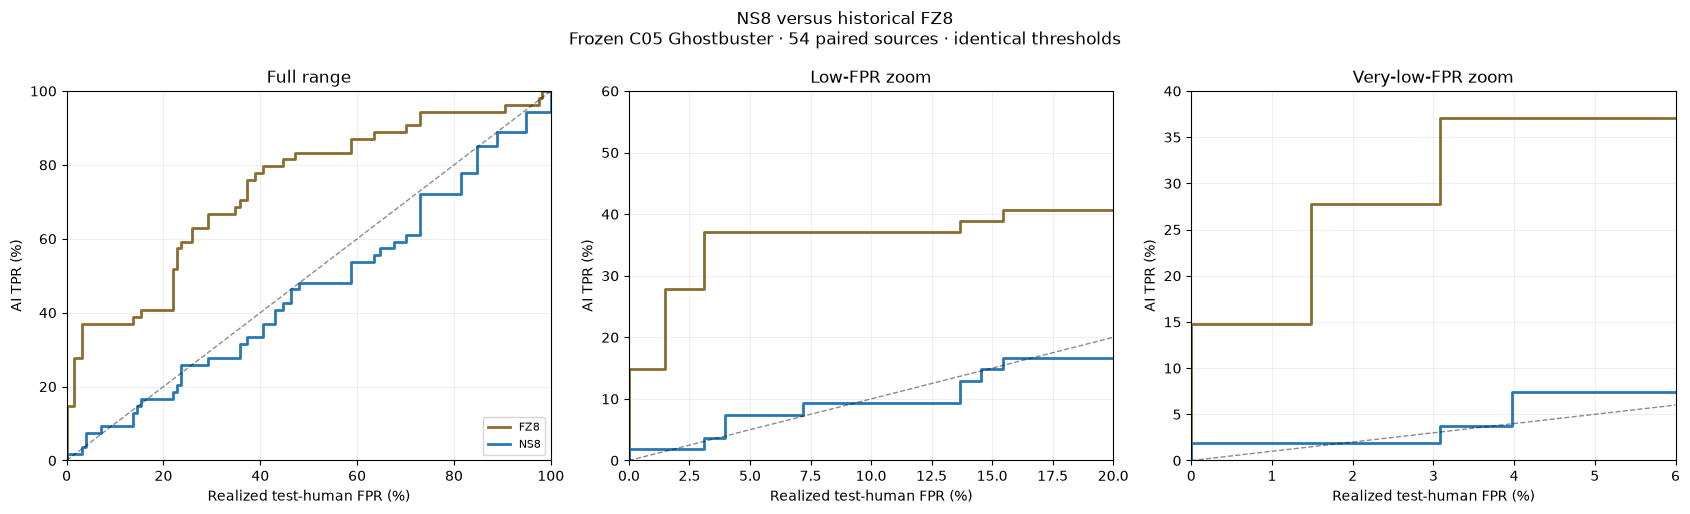

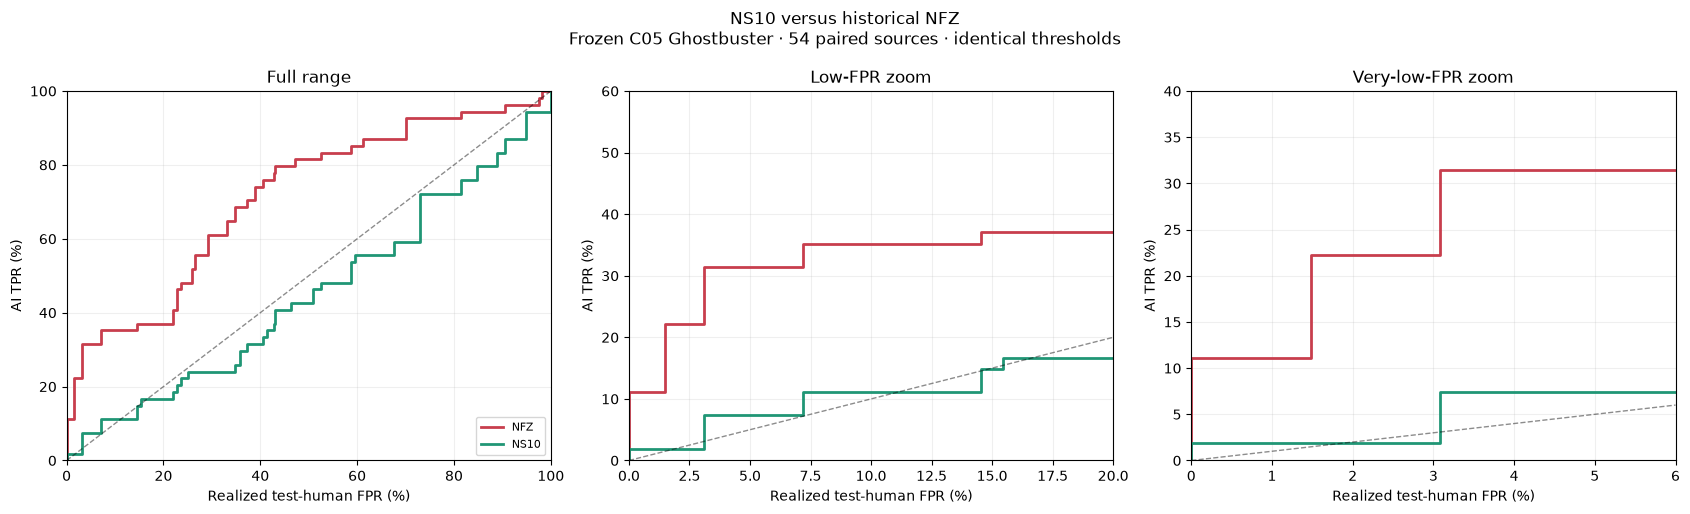

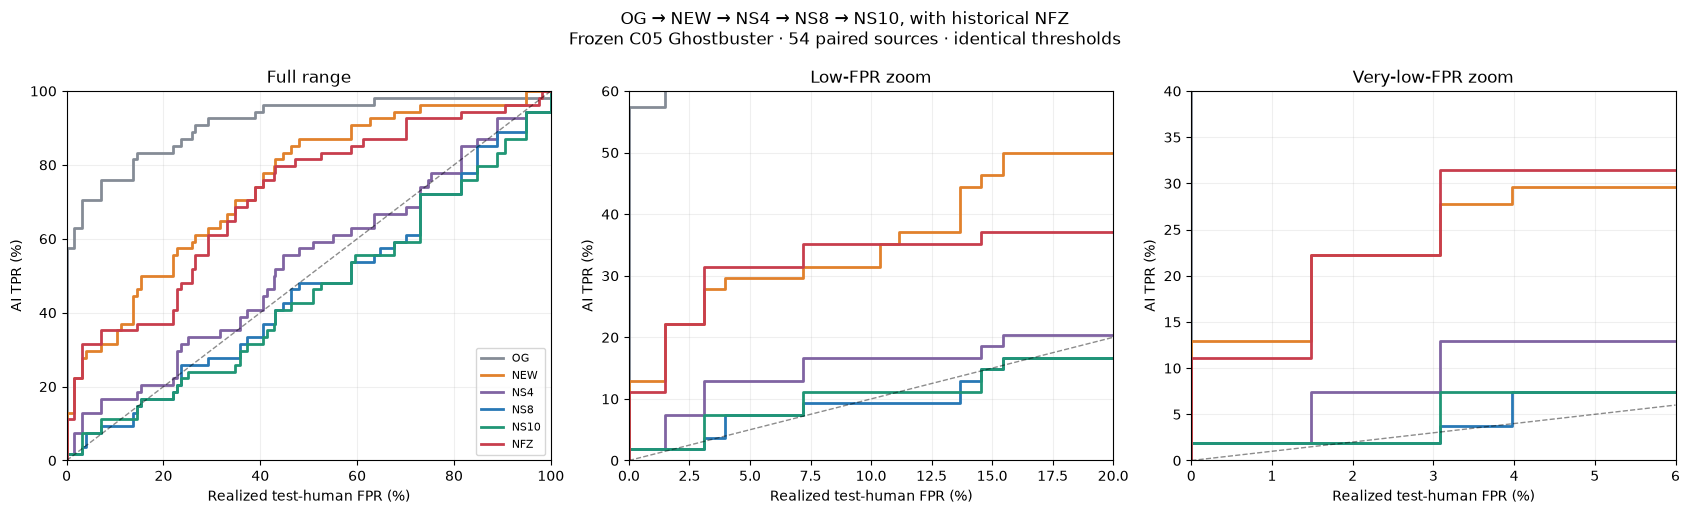

NS8: ../results/causal/C06b_NEW_steps5_10_v1/NS8_texts.csv
NS10: ../results/causal/C06b_NEW_steps5_10_v1/NS10_texts.csv
Figures and all per-case checkpoints saved: ../results/causal/C06b_NEW_steps5_10_v1


In [14]:
COLORS={'OG':'#858C96','NEW':'#E1812C','NS4':'#8064A2','NS8':'#2878B5','NS10':'#209675','NFZ':'#C83E4D','FZ8':'#8C6D31'}
def plot_staircase(names,stem,title):
    series={name:SCORES[name] for name in names}
    st=staircase(cal_scores,wc,human_scores,wh,series)
    atomic_csv(st,OUT/(stem+'.csv'))
    fig,axs=plt.subplots(1,3,figsize=(17,5.2))
    for ax,(xlim,ylim,title_) in zip(axs,[((0,100),(0,100),'Full range'),((0,20),(0,60),'Low-FPR zoom'),((0,6),(0,40),'Very-low-FPR zoom')]):
        for name in names:ax.step(st.test_FPR*100,st[name]*100,where='post',lw=2,label=name,color=COLORS[name])
        hi=min(xlim[1],ylim[1]);ax.plot([0,hi],[0,hi],'--',color='black',lw=1,alpha=.45)
        ax.set(xlim=xlim,ylim=ylim,title=title_,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
    axs[0].legend(loc='lower right',fontsize=8)
    fig.suptitle(title+'\nFrozen C05 Ghostbuster · 54 paired sources · identical thresholds')
    fig.tight_layout()
    for folder in [OUT/'figures',FIG]:
        for ext in ['png','pdf']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)
summary=pd.DataFrame([dict(stage=k,cases=54,AUROC=weighted_auc(human_scores,wh,SCORES[k]),mean_AI_score=float(SCORES[k].mean()),median_AI_score=float(np.median(SCORES[k]))) for k in ['OG','NEW','NS4','NS8','NS10','FZ8','NFZ']])
atomic_csv(summary,OUT/'stage_summary.csv');display(summary.round(6))
plot_staircase(['FZ8','NS8'],'C06b_NS8_vs_FZ8_TPR_staircase','NS8 versus historical FZ8')
plot_staircase(['NFZ','NS10'],'C06b_NS10_vs_NFZ_TPR_staircase','NS10 versus historical NFZ')
plot_staircase(['OG','NEW','NS4','NS8','NS10','NFZ'],'C06b_all_stages_TPR_staircase','OG → NEW → NS4 → NS8 → NS10, with historical NFZ')
paired=NS4[['case_id','source_id','domain']].copy()
for k,v in SCORES.items():paired[k]=v
atomic_csv(paired,OUT/'paired_AI_scores.csv')
print('NS8:',OUT/'NS8_texts.csv')
print('NS10:',OUT/'NS10_texts.csv')
print('Figures and all per-case checkpoints saved:',OUT)


## Reading the comparisons

FZ8 is the historical Step-8 text set, scored by Ghostbuster here; NFZ is the historical Step-10 set. Lower TPR at the same realized human FPR means fewer AI texts detected. Stage comparisons preserve all 54 sources, including unchanged edits and token-capped generation inputs. A residual target gap is an editing outcome, not grounds for excluding a document.

For a plotting-only rerun, load the three `*_TPR_staircase.csv` files. Neither generation nor probability scoring needs repeating. Check `NS8_manual_review.csv`, `NS10_manual_review.csv`, and per-step JSON logs for content preservation.


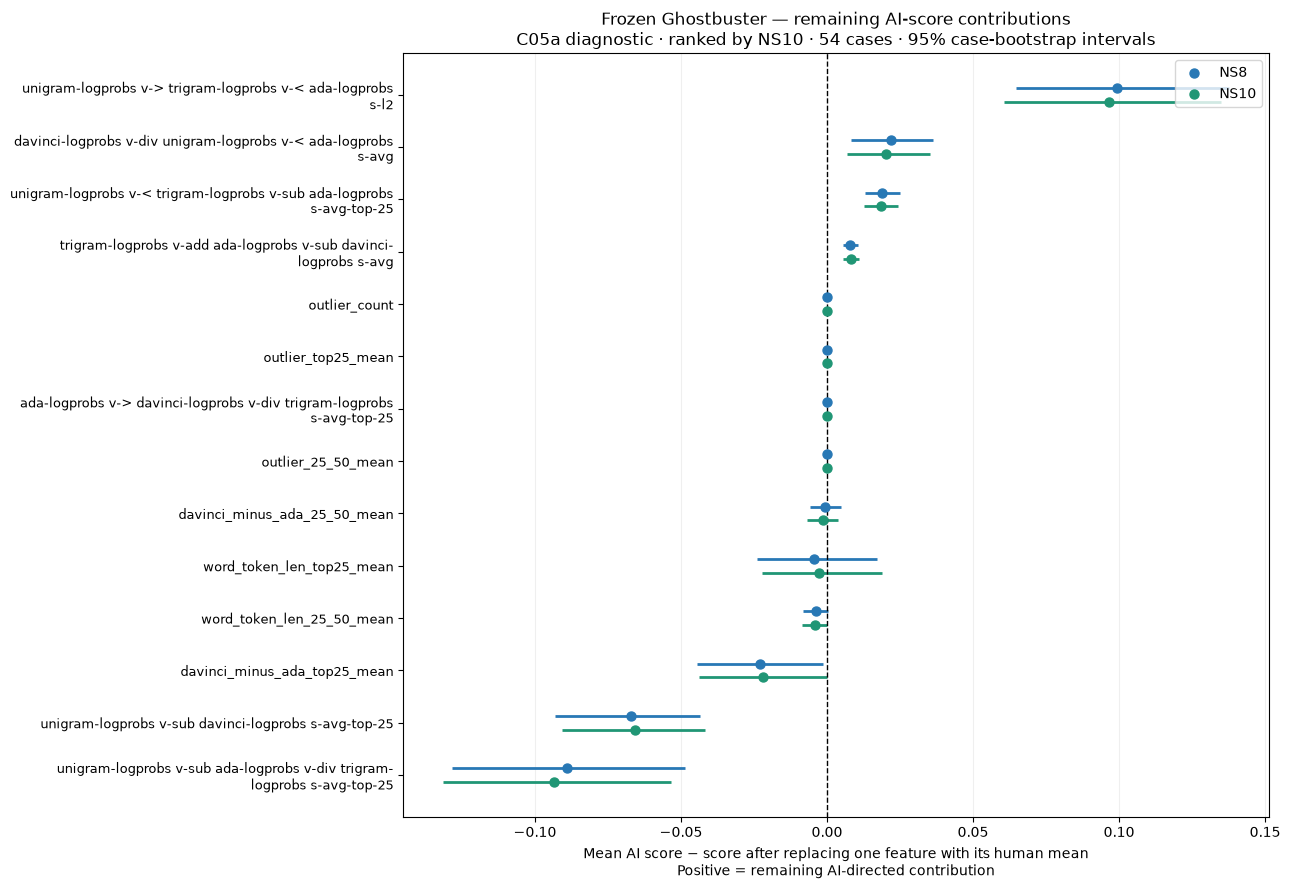

,rank,feature,mean_AI_score_contribution,ci_low,ci_high,n_score_lowered,n_score_raised,cases
0,1,unigram-logprobs v-> trigram-logprobs v-< ada-...,0.09661,0.06072,0.13502,47,7,54
1,2,davinci-logprobs v-div unigram-logprobs v-< ad...,0.02016,0.00684,0.03528,16,33,54
2,3,unigram-logprobs v-< trigram-logprobs v-sub ad...,0.01841,0.01283,0.02420,51,3,54
3,4,trigram-logprobs v-add ada-logprobs v-sub davi...,0.00809,0.00553,0.01083,46,8,54
4,5,outlier_count,0.00000,0.00000,0.00000,0,0,54
5,6,outlier_top25_mean,0.00000,0.00000,0.00000,0,0,54
6,7,ada-logprobs v-> davinci-logprobs v-div trigra...,0.00000,0.00000,0.00000,0,0,54
7,8,outlier_25_50_mean,0.00000,0.00000,0.00000,0,0,54
8,9,davinci_minus_ada_25_50_mean,-0.00149,-0.00674,0.00365,24,30,54
9,10,word_token_len_top25_mean,-0.00278,-0.02219,0.01886,21,33,54


Each value is an actual one-feature counterfactual score difference. These differences are not additive and need not sum to the AI score.
Saved: ../results/causal/C06b_NEW_steps5_10_v1/figures/C06b_AI_score_contributions.png


In [16]:
# C05a-style AI-score contribution audit for NS8 and NS10.
# Uses the actual frozen calibrated Ghostbuster classifier.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill

audit_names = list(FEATURE_NAMES)

# Same-genre test-human feature means, matching C05a.
assert (
    raid_features.doc_key.to_numpy() == raid_eval.doc_key.to_numpy()
).all()

audit_hmask = (
    raid_eval["split"].eq("test") & raid_eval["label"].eq(0)
).to_numpy()

audit_human = raid_features.loc[audit_hmask, audit_names].copy()
audit_human["domain"] = raid_eval.loc[audit_hmask, "domain"].to_numpy()
audit_human_mean = audit_human.groupby("domain")[audit_names].mean()

audit_rows, audit_cases = [], []

for stage in ["NS8", "NS10"]:
    frame = pd.read_csv(OUT / f"{stage}_features.csv")
    assert len(frame) == 54 and frame.case_id.is_unique
    frame = frame.set_index("case_id").loc[CASES].reset_index()

    saved = (
        pd.read_csv(OUT / f"{stage}_scores.csv")
        .set_index("case_id").loc[CASES]
    )
    assert frame.domain.isin(audit_human_mean.index).all()

    actual_score = frozen_predict(frame)
    np.testing.assert_allclose(
        actual_score, saved.AI_score.to_numpy(),
        rtol=1e-7, atol=1e-9,
    )

    for j, feature in enumerate(audit_names):
        reference = audit_human_mean.loc[
            frame.domain, feature
        ].to_numpy(float)

        counterfactual = frame.copy()
        counterfactual[feature] = reference
        cf_score = frozen_predict(counterfactual)

        # Exact C05a diagnostic, in AI-probability units.
        drop = actual_score - cf_score

        rng = np.random.default_rng(20260914 + j)
        draws = rng.integers(0, len(drop), size=(5000, len(drop)))
        boot = drop[draws].mean(axis=1)
        lo, hi = np.quantile(boot, [0.025, 0.975])

        audit_rows.append({
            "stage": stage,
            "feature": feature,
            "mean_AI_score_contribution": drop.mean(),
            "ci_low": lo,
            "ci_high": hi,
            "n_score_lowered": int((drop > 1e-12).sum()),
            "n_score_raised": int((drop < -1e-12).sum()),
            "cases": len(drop),
        })

        case = frame[["case_id", "source_id", "domain"]].copy()
        case["stage"] = stage
        case["feature"] = feature
        case["raw_value"] = frame[feature].to_numpy()
        case["same_genre_human_mean"] = reference
        case["AI_score"] = actual_score
        case["counterfactual_AI_score"] = cf_score
        case["score_drop"] = drop
        audit_cases.append(case)

score_audit = pd.DataFrame(audit_rows)
ns10_ranking = (
    score_audit.loc[score_audit.stage.eq("NS10")]
    .sort_values("mean_AI_score_contribution", ascending=False)
    .reset_index(drop=True)
)
ns10_ranking.insert(0, "rank", np.arange(1, len(ns10_ranking) + 1))
feature_order = ns10_ranking.feature.tolist()

fig, ax = plt.subplots(figsize=(13, 9))
y = np.arange(len(feature_order))

for stage, offset, color in [
    ("NS8", -0.13, "#2878B5"),
    ("NS10", 0.13, "#209675"),
]:
    s = (
        score_audit.loc[score_audit.stage.eq(stage)]
        .set_index("feature").loc[feature_order]
    )
    ax.hlines(y + offset, s.ci_low, s.ci_high, color=color, lw=2)
    ax.scatter(
        s.mean_AI_score_contribution, y + offset,
        color=color, s=42, label=stage, zorder=3,
    )

ax.axvline(0, color="black", linestyle="--", lw=1)
ax.set_yticks(y)
ax.set_yticklabels([fill(f, 57) for f in feature_order], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel(
    "Mean AI score − score after replacing one feature with its human mean\n"
    "Positive = remaining AI-directed contribution"
)
ax.set_title(
    "Frozen Ghostbuster — remaining AI-score contributions\n"
    "C05a diagnostic · ranked by NS10 · 54 cases · 95% case-bootstrap intervals"
)
ax.grid(axis="x", alpha=0.2)
ax.legend()
fig.tight_layout()

audit_dest = OUT / "figures"
audit_dest.mkdir(parents=True, exist_ok=True)
for ext in ["png", "pdf"]:
    fig.savefig(
        audit_dest / f"C06b_AI_score_contributions.{ext}",
        dpi=300, bbox_inches="tight",
    )
plt.show()

score_audit.to_csv(OUT / "AI_score_contributions_summary.csv", index=False)
ns10_ranking.to_csv(OUT / "NS10_AI_score_contributions_ranked.csv", index=False)
pd.concat(audit_cases, ignore_index=True).to_csv(
    OUT / "AI_score_counterfactuals_per_case.csv", index=False
)

display(ns10_ranking.drop(columns="stage").round(5))
print(
    "Each value is an actual one-feature counterfactual score difference. "
    "These differences are not additive and need not sum to the AI score."
)
print("Saved:", audit_dest / "C06b_AI_score_contributions.png")